In [7]:
import numpy as np
import pandas as pd
import pypsa
import matplotlib.pyplot as plt

#n = pypsa.Network(
#    r"C:\Users\jonat\pypsa-eur-november\pypsa-eur\results\sector_NE_june_july_2025\networks\base_s_10___2025.nc"
#)
n = pypsa.Network(
    r"C:\Users\frede\Master_Thesis_Private\results\sector_2035_w_V2G\networks\base_s_10___2035.nc"
)

INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.4)
INFO:pypsa.network.io:Imported network 'Unnamed Network' has buses, carriers, generators, global_constraints, lines, links, loads, storage_units, stores, sub_networks


In [8]:
# Find H2-to-power links
mask = n.links.carrier.str.contains("H2 turbine|H2 Fuel Cell", case=False)
h2 = n.links.loc[mask, ["carrier", "bus0", "bus1", "p_nom", "p_nom_extendable",
                        "p_nom_opt", "efficiency"]].copy()

# p_nom refers to bus0 (H2 input) -> convert to electric output capacity
h2["p_nom_opt_el_MW"] = h2.p_nom_opt * h2.efficiency
h2["built_MW_el"] = (h2.p_nom_opt - h2.p_nom).clip(lower=0) * h2.efficiency

print(h2)
print(f"\nTotal H2 turbine capacity: {h2.p_nom_opt_el_MW.sum():.1f} MW_el")
print(f"Of which newly built:     {h2.built_MW_el.sum():.1f} MW_el")

# Did they actually run? Electric output is -p1 (p1 is negative for output)
if mask.any():
    gen_MWh = (-n.links_t.p1.loc[:, mask]).mul(n.snapshot_weightings.generators, axis=0).sum()
    print("\nElectricity generated (MWh):")
    print(gen_MWh[gen_MWh > 1e-3])

                           carrier        bus0     bus1  p_nom  \
name                                                             
DE2 0AC H2 Fuel Cell  H2 Fuel Cell  DE2 0AC H2  DE2 0AC    0.0   
DK0 0AC H2 Fuel Cell  H2 Fuel Cell  DK0 0AC H2  DK0 0AC    0.0   
DK2 0AC H2 Fuel Cell  H2 Fuel Cell  DK2 0AC H2  DK2 0AC    0.0   
FI0 0AC H2 Fuel Cell  H2 Fuel Cell  FI0 0AC H2  FI0 0AC    0.0   
GB1 0AC H2 Fuel Cell  H2 Fuel Cell  GB1 0AC H2  GB1 0AC    0.0   
GB3 0AC H2 Fuel Cell  H2 Fuel Cell  GB3 0AC H2  GB3 0AC    0.0   
GB4 0AC H2 Fuel Cell  H2 Fuel Cell  GB4 0AC H2  GB4 0AC    0.0   
NL2 0AC H2 Fuel Cell  H2 Fuel Cell  NL2 0AC H2  NL2 0AC    0.0   
NO0 0AC H2 Fuel Cell  H2 Fuel Cell  NO0 0AC H2  NO0 0AC    0.0   
SE0 0AC H2 Fuel Cell  H2 Fuel Cell  SE0 0AC H2  SE0 0AC    0.0   

                      p_nom_extendable  p_nom_opt  efficiency  \
name                                                            
DE2 0AC H2 Fuel Cell              True   0.013441         0.5   
DK0 0AC H2 F

In [9]:
%config InlineBackend.figure_format = "retina"   # 2x pixel density in the notebook
plt.rcParams["figure.dpi"] = 150                 # inline display resolution (default ~100)
plt.rcParams["savefig.dpi"] = 300                # resolution for fig.savefig(...)

# Save every figure shown in this notebook as SVG (vector - stays sharp in PowerPoint).
import os, re

FIG_DIR = "figures_svg"
os.makedirs(FIG_DIR, exist_ok=True)
_orig_show = getattr(plt, "_orig_show", plt.show)  # avoid double-wrapping on re-run
plt._orig_show = _orig_show
_fig_counter = [0]


def _show_and_save(*args, **kwargs):
    for num in plt.get_fignums():
        fig = plt.figure(num)
        title = (fig._suptitle.get_text() if fig._suptitle else
                 next((ax.get_title() for ax in fig.axes if ax.get_title()), f"fig_{num}"))
        _fig_counter[0] += 1
        name = re.sub(r"[^\w\- ]", "_", title).strip()[:80]
        fig.savefig(f"{FIG_DIR}/{_fig_counter[0]:02d}_{name}.svg", bbox_inches="tight")
    _orig_show(*args, **kwargs)


plt.show = _show_and_save


In [10]:

# Carriers that only move energy between buses (not real capacity) - extend as needed
EXCLUDE = {"DC", "AC", "electricity distribution grid", "load", "load shedding",
           "household heat delivery"}
MIN_GW = 1e-3  # hide bars smaller than this


# Map PyPSA-Eur cluster names (country + AC sub-network + cluster + carrier)
# to readable names. Valid for sector_NE runs (10 clusters) - check per run.
NODE_NAMES = {
    "DK0 0AC": "DK2 (East DK)",
    "DK2 0AC": "DK1 (West DK)",
    "DE2 0AC": "DE",
    "NL2 0AC": "NL",
    "NO0 0AC": "NO",
    "SE0 0AC": "SE",
    "FI0 0AC": "FI",
    "GB1 0AC": "GB (mainland)",
    "GB3 0AC": "GB (Orkney/Shetland)",
    "GB4 0AC": "GB (N. Ireland)",
}


def _loc(n):
    loc = n.buses.location.copy() if "location" in n.buses else pd.Series("", index=n.buses.index)
    loc = loc.where(loc.astype(str) != "", n.buses.index.to_series())
    return loc.map(lambda x: NODE_NAMES.get(x, x))

def _mean_eff(n, eff_col, idx):
    """Static efficiency, overwritten with weighted time-mean where time-varying."""
    eff = n.links.loc[idx, eff_col].astype(float).copy()
    try:
        tv = n.links_t[eff_col]
    except (KeyError, AttributeError):
        tv = pd.DataFrame()
    cols = tv.columns.intersection(idx)
    if len(cols):
        w = n.snapshot_weightings.generators
        eff.loc[cols] = tv[cols].mul(w, axis=0).sum() / w.sum()
    return eff


def output_capacities(n, bus_carriers, exclude=EXCLUDE):
    """Output-side capacity [GW] per (node, carrier) on buses with carrier in bus_carriers."""
    bus_carriers = [bus_carriers] if isinstance(bus_carriers, str) else list(bus_carriers)
    bc, loc = n.buses.carrier, _loc(n)
    frames = []

    # Generators and storage units: p_nom is already output capacity
    for c in [n.generators, n.storage_units]:
        if c.empty:
            continue
        m = c.bus.map(bc).isin(bus_carriers)
        frames.append(pd.DataFrame({"node": c.bus[m].map(loc),
                                    "carrier": c.carrier[m],
                                    "cap": c.p_nom_opt[m]}))

    # Links: p_nom is input (bus0) -> multiply by efficiency of each output port
    # Links: normal links take input at bus0 -> output = p_nom * efficiencyX at bus1..N.
    # Reversed links (p_max_pu <= 0, e.g. heat pumps here) output at bus0 with p_nom
    # already in output units; their other ports are inputs and are skipped.
    L = n.links
    rev = L.p_max_pu.le(0)
    try:
        rev |= n.links_t.p_max_pu.le(0).all().reindex(L.index, fill_value=False)
    except (KeyError, AttributeError):
        pass

    m = rev & L.bus0.map(bc).isin(bus_carriers)
    frames.append(pd.DataFrame({"node": L.bus0[m].map(loc),
                                "carrier": L.carrier[m],
                                "cap": L.p_nom_opt[m]}))

    Lf = L[~rev]
    ports = sorted(int(col[3:]) for col in Lf.columns
                   if col.startswith("bus") and col[3:].isdigit() and col != "bus0")
    for p in ports:
        bus = Lf[f"bus{p}"]
        m = bus.map(bc).isin(bus_carriers)
        if not m.any():
            continue
        eff_col = "efficiency" if p == 1 else f"efficiency{p}"
        if eff_col not in Lf:
            continue
        idx = Lf.index[m]
        cap = Lf.loc[idx, "p_nom_opt"] * _mean_eff(n, eff_col, idx)
        frames.append(pd.DataFrame({"node": bus[idx].map(loc),
                                    "carrier": Lf.loc[idx, "carrier"],
                                    "cap": cap}))

    df = pd.concat(frames, ignore_index=True)
    df = df[~df.carrier.isin(exclude) & (df.cap > 0)]
    df = df.groupby(["node", "carrier"], as_index=False).cap.sum()
    df["cap"] /= 1e3  # MW -> GW
    return df[df.cap >= MIN_GW]


def _colors(n, carriers):
    cmap = plt.get_cmap("tab20")
    col = n.carriers.color if "color" in n.carriers else pd.Series(dtype=str)
    out = []
    for i, c in enumerate(carriers):
        v = col.get(c, "")
        out.append(v if isinstance(v, str) and v.strip() else cmap(i % 20))
    return out



STORAGE_KW = ("discharger", "PHS", "hydro", "battery")


def _storage_energy_gwh(n, node, carrier):
    """Energy capacity [GWh] behind a storage discharger / StorageUnit at node."""
    loc = _loc(n)
    su = n.storage_units[(n.storage_units.carrier == carrier)
                         & (n.storage_units.bus.map(loc) == node)]
    if len(su):
        return (su.p_nom_opt * su.max_hours).sum() / 1e3
    if carrier.endswith(" discharger"):
        store_carrier = carrier.removesuffix(" discharger")
        st = n.stores[(n.stores.carrier == store_carrier)
                      & (n.stores.bus.map(loc) == node)]
        return st.e_nom_opt.sum() / 1e3
    return np.nan

def plot_capacity_by_node(n, df, title, figsize=(8, 5)):
    if df.empty:
        print(f"No capacity found for: {title}")
        return
    for node in sorted(df.node.unique()):
        s = df[df.node == node].set_index("carrier").cap.sort_values(ascending=False)

        fig, ax = plt.subplots(figsize=figsize)
        bars = ax.bar(s.index, s.values, color=_colors(n, s.index), edgecolor="k", lw=0.5)
        labels = []
        for bar, (car, v) in zip(bars, s.items()):
            lab = f"{v:.1f}" if v >= 10 else f"{v:.2f}"
            if any(k in car for k in STORAGE_KW):
                bar.set_hatch("//")
                e = _storage_energy_gwh(n, node, car)
                if np.isfinite(e) and e > 0:
                    lab += f"\n{e:.1f} GWh"
            labels.append(lab)
        ax.bar_label(bars, labels=labels, padding=2, fontsize=9)
        ax.set_ylim(0, s.max() * 1.25)
        ax.set_title(f"{title} – {node}")
        ax.set_ylabel("Capacity [GW]")
        ax.tick_params(axis="x", rotation=60)
        plt.setp(ax.get_xticklabels(), ha="right")
        ax.grid(axis="y", alpha=0.3)
        fig.tight_layout()
        plt.show()


def _bar_panel(ax, n, s, node, panel_title, unit):
    """Draw one bar panel for a node; s = capacity [GW] indexed by carrier."""
    ax.set_title(panel_title)
    if s.empty:
        ax.text(0.5, 0.5, "no capacity", ha="center", va="center", transform=ax.transAxes)
        ax.set_xticks([])
        ax.set_yticks([])
        return
    s = s.sort_values(ascending=False)
    bars = ax.bar(s.index, s.values, color=_colors(n, s.index), edgecolor="k", lw=0.5)
    labels = []
    for bar, (car, v) in zip(bars, s.items()):
        lab = f"{v:.1f}" if v >= 10 else f"{v:.2f}"
        if any(k in car for k in STORAGE_KW):
            bar.set_hatch("//")
            e = _storage_energy_gwh(n, node, car)
            if np.isfinite(e) and e > 0:
                lab += f"\n{e:.1f} GWh"
        labels.append(lab)
    ax.bar_label(bars, labels=labels, padding=2, fontsize=9)
    ax.set_ylim(0, s.max() * 1.25)
    ax.set_ylabel(f"Capacity [{unit}]")
    ax.tick_params(axis="x", rotation=60)
    plt.setp(ax.get_xticklabels(), ha="right")
    ax.grid(axis="y", alpha=0.3)


In [11]:
PANELS = {
    "Electricity":          (["AC", "low voltage"],     "GW_el"),
    "Urban central heat":   (["urban central heat"],    "GW_th"),
    "Urban decentral heat": (["urban decentral heat"],  "GW_th"),
    "Rural heat":           (["rural heat"],            "GW_th"),
}


def plot_node_overview(n, panels=PANELS, figsize=(18, 12), save_dir=None):
    """One 2x2 figure per node: electricity + the three heat systems."""
    dfs = {name: output_capacities(n, bus_carriers) for name, (bus_carriers, _) in panels.items()}
    nodes = sorted(set().union(*(df.node for df in dfs.values())))

    for node in nodes:
        fig, axes = plt.subplots(2, 2, figsize=figsize)
        for ax, (name, (_, unit)) in zip(axes.flat, panels.items()):
            df = dfs[name]
            s = df[df.node == node].set_index("carrier").cap
            _bar_panel(ax, n, s, node, name, unit)

        fig.suptitle(node, fontsize=18, fontweight="bold")
        fig.tight_layout()
        if save_dir:
            safe = "".join(c if c.isalnum() or c in "-_ " else "_" for c in node)
            fig.savefig(f"{save_dir}/capacity_{safe}.png", dpi=200, bbox_inches="tight")
        plt.show()

    return dfs

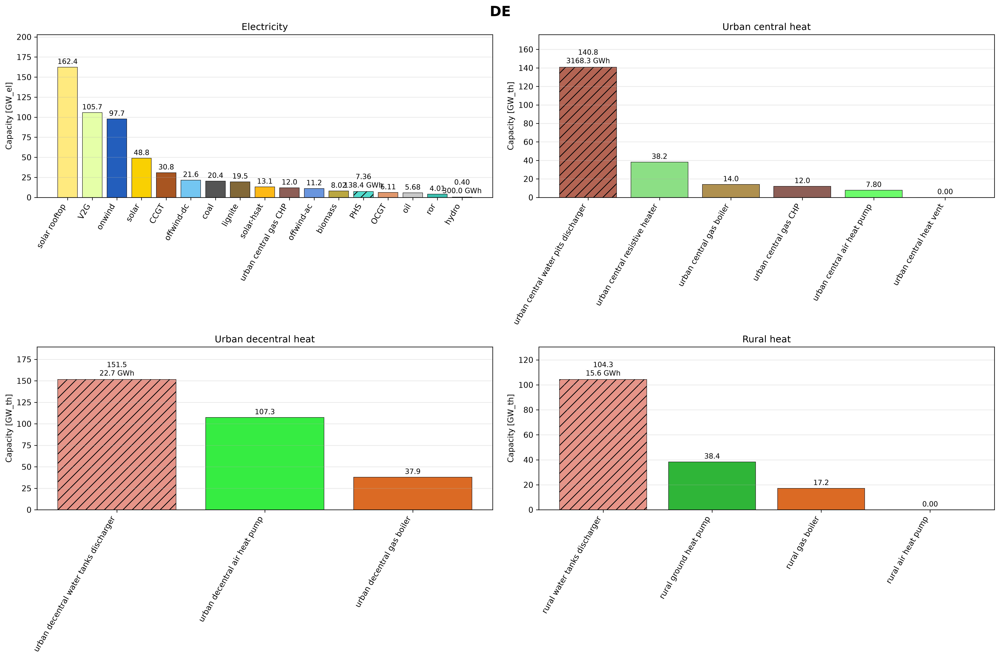

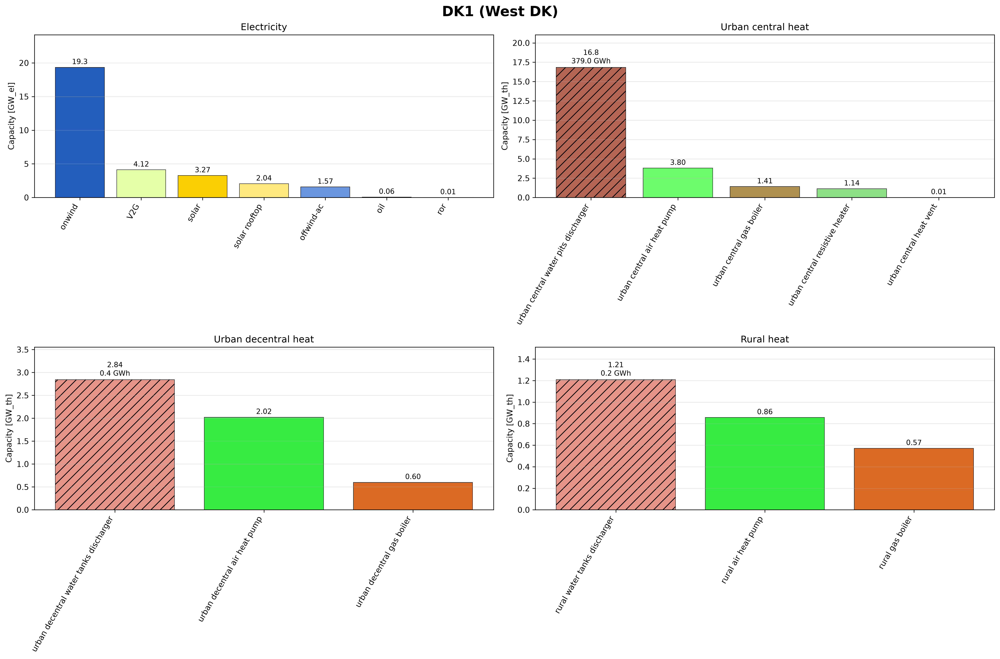

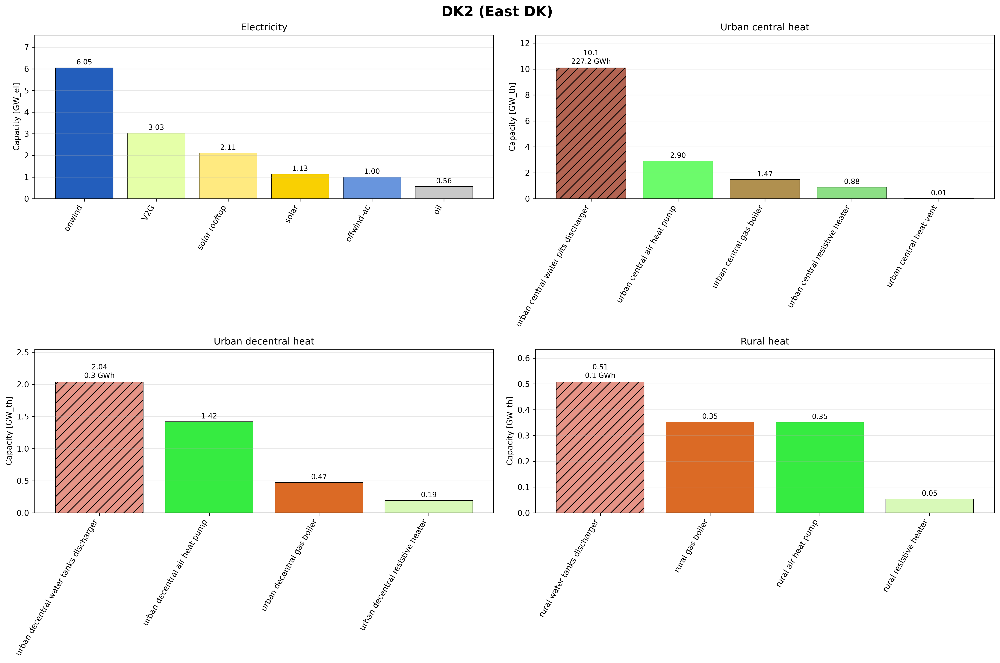

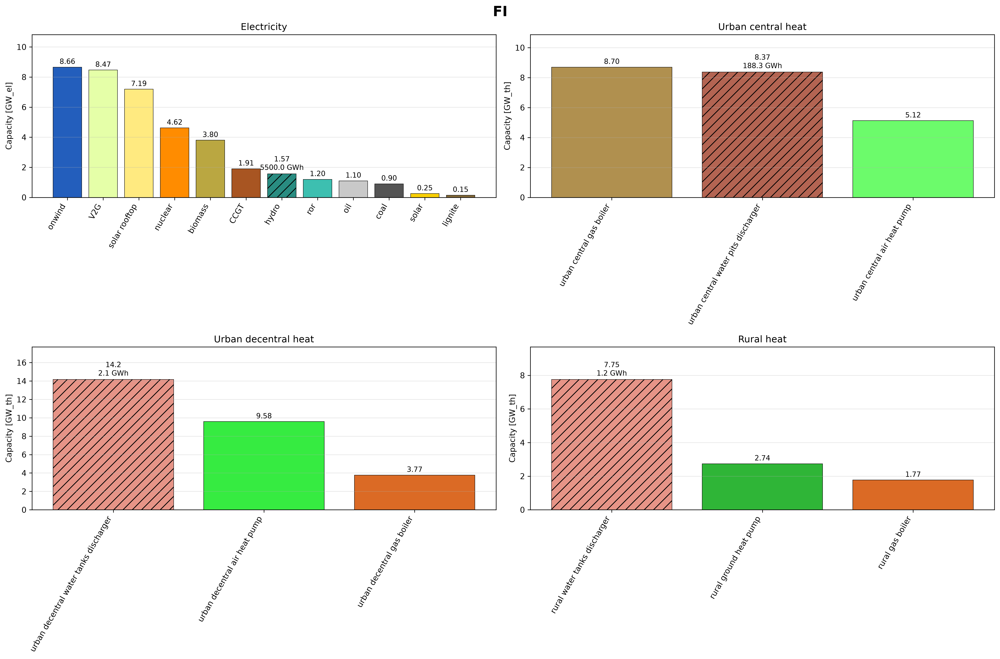

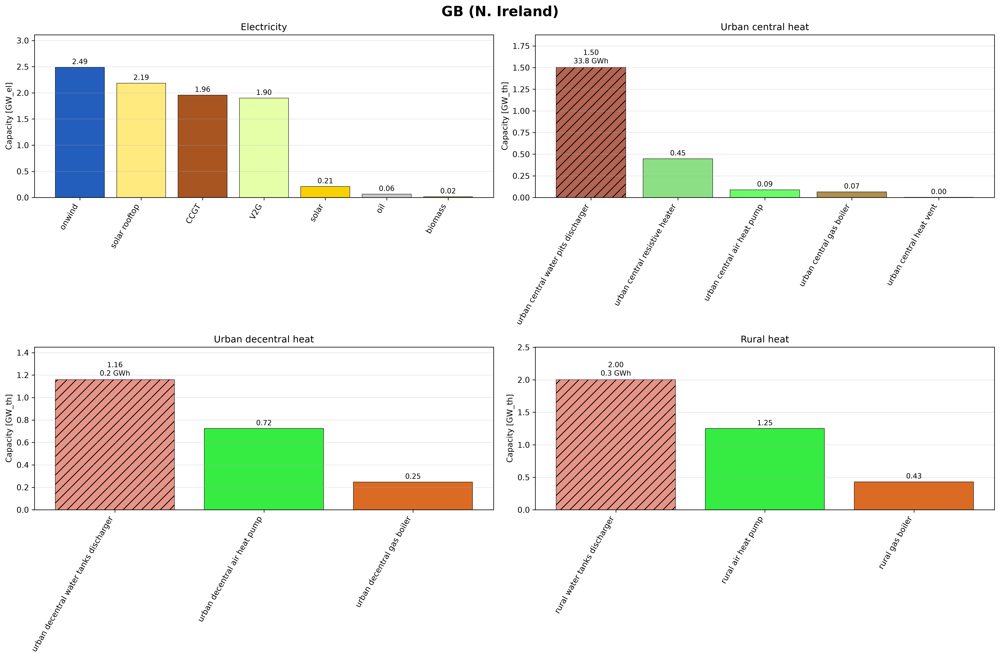

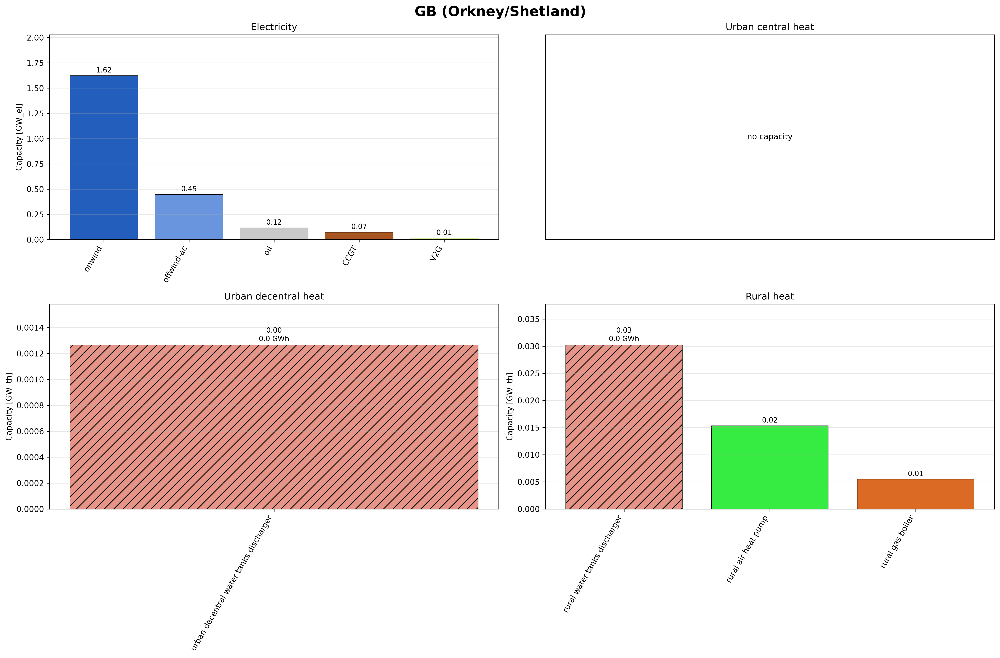

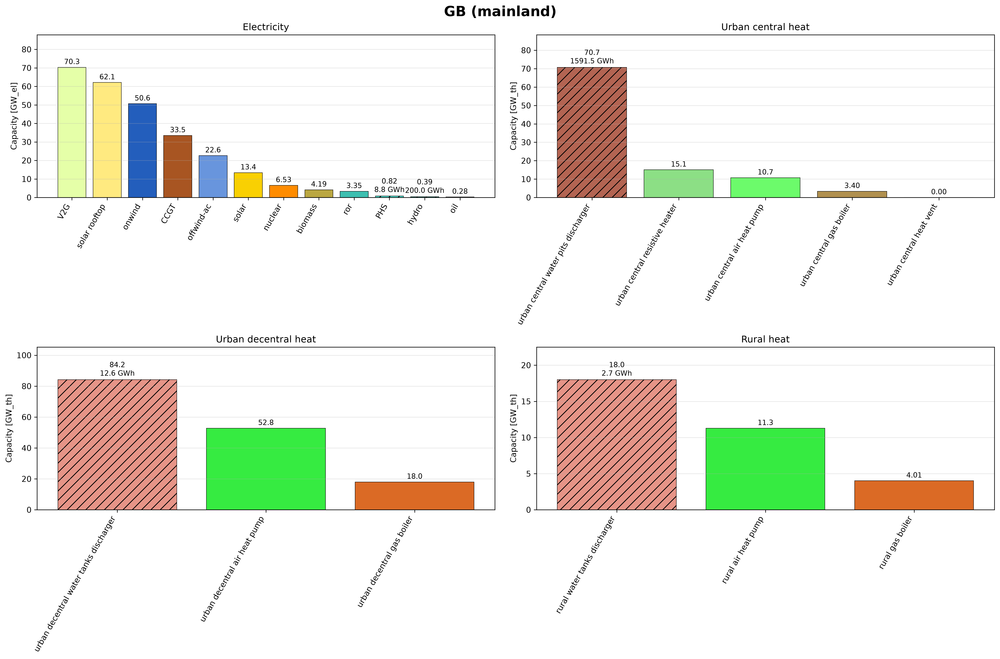

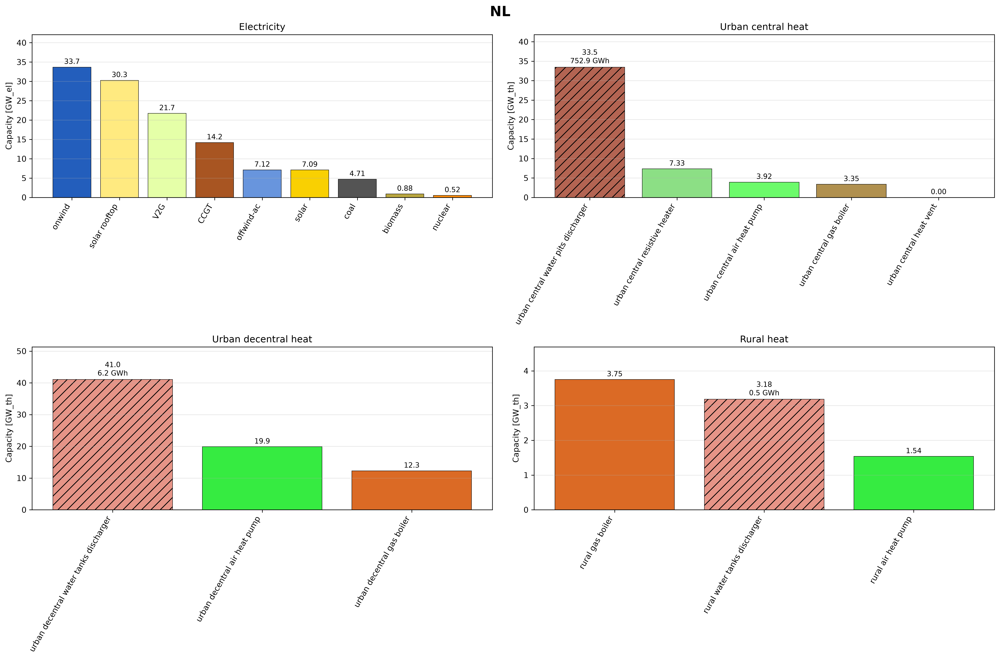

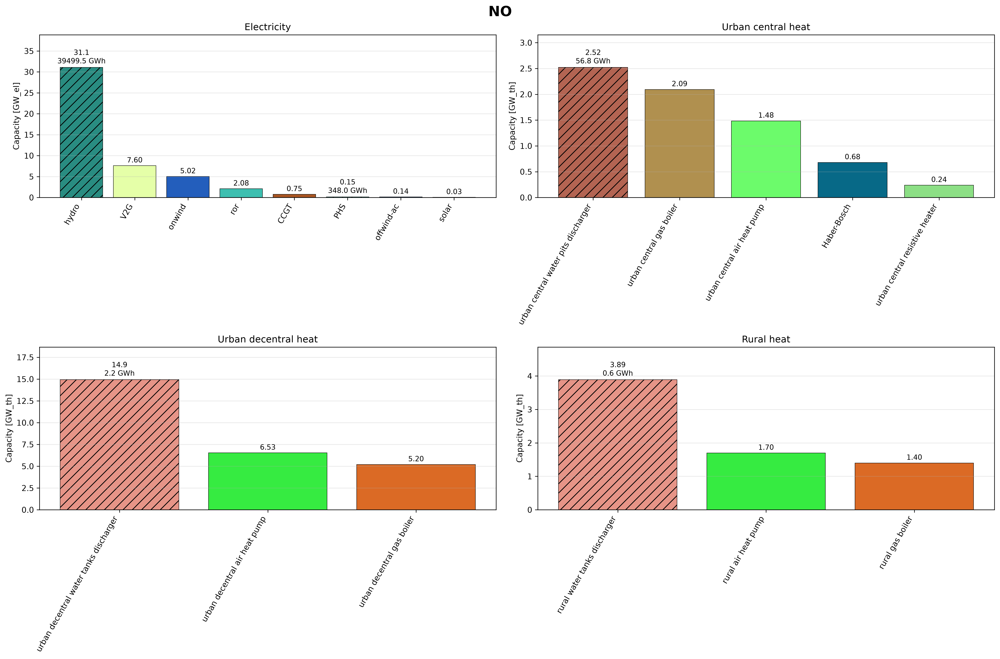

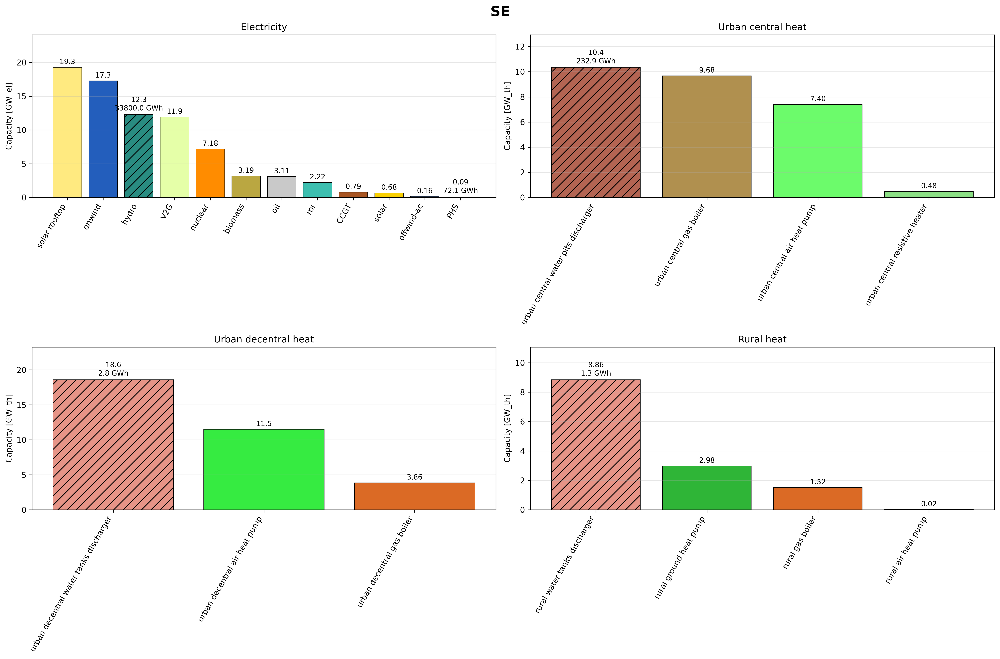

node,DE,DK1 (West DK),DK2 (East DK),FI,GB (N. Ireland),GB (mainland),NL,NO,SE
carrier,,,,,,,,,
Haber-Bosch,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.678,NaN
urban central air heat pump,7.799,3.803,2.900,5.124,0.089,10.748,3.923,1.485,7.401
urban central gas CHP,11.990,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
urban central gas boiler,13.978,1.414,1.469,8.699,0.066,3.395,3.355,2.094,9.678
urban central heat vent,0.002,0.011,0.010,NaN,0.002,0.002,0.002,NaN,NaN
urban central resistive heater,38.193,1.143,0.885,NaN,0.448,15.056,7.331,0.238,0.477
urban central water pits discharger,140.814,16.842,10.099,8.369,1.503,70.734,33.463,2.523,10.351


In [12]:
dfs = plot_node_overview(n)
# dfs = plot_node_overview(n, save_dir="figures")   # also save one PNG per node

# Tables, e.g.:
dfs["Urban central heat"].pivot(index="carrier", columns="node", values="cap").round(3)

In [6]:
def plot_stacked_by_node(n, df, title, unit, nodes=None, min_label_share=0.03, figsize=(9, 7)):
    """One stacked bar per node, segments = carriers, with GW labels."""
    if nodes is not None:
        df = df[df.node.isin(nodes)]
    if df.empty:
        print(f"No capacity found for: {title}")
        return
    tab = df.pivot_table(index="carrier", columns="node", values="cap", aggfunc="sum").fillna(0)
    tab = tab.loc[tab.sum(axis=1).sort_values(ascending=False).index]  # biggest at bottom
    totals = tab.sum()

    fig, ax = plt.subplots(figsize=figsize)
    bottom = pd.Series(0.0, index=tab.columns)
    for car, color in zip(tab.index, _colors(n, tab.index)):
        vals = tab.loc[car]
        bars = ax.bar(tab.columns, vals, bottom=bottom, color=color, edgecolor="k", lw=0.5,
                      label=car, width=0.6,
                      hatch="//" if any(k in car for k in STORAGE_KW) else None)
        # value inside segment if it is big enough to read
        ax.bar_label(bars, labels=[f"{v:.2f}" if v >= min_label_share * totals.max() else ""
                                   for v in vals], label_type="center", fontsize=8)
        bottom += vals

    for i, node in enumerate(tab.columns):
        ax.text(i, totals[node] * 1.01, f"{totals[node]:.2f} {unit}",
                ha="center", va="bottom", fontweight="bold")
    ax.set_ylim(0, totals.max() * 1.08)
    ax.set_ylabel(f"Capacity [{unit}]")
    ax.set_title(title)
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles[::-1], labels[::-1], bbox_to_anchor=(1.01, 1), loc="upper left",
              fontsize=8, frameon=False)  # reversed so legend order matches the stack
    fig.tight_layout()
    plt.show()

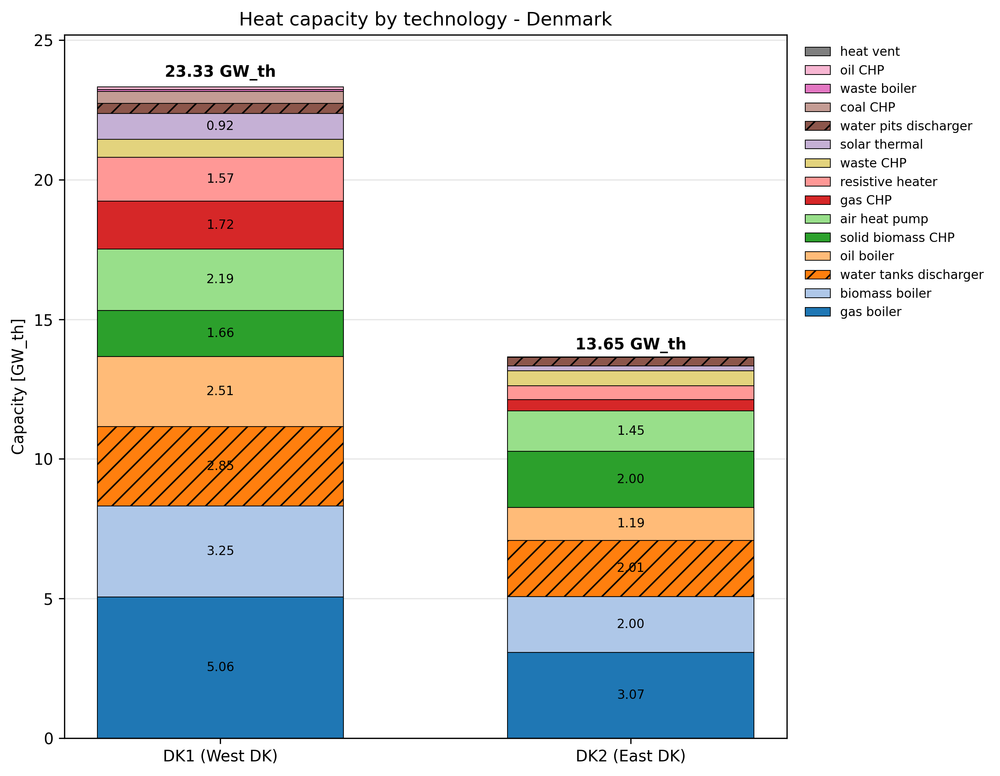

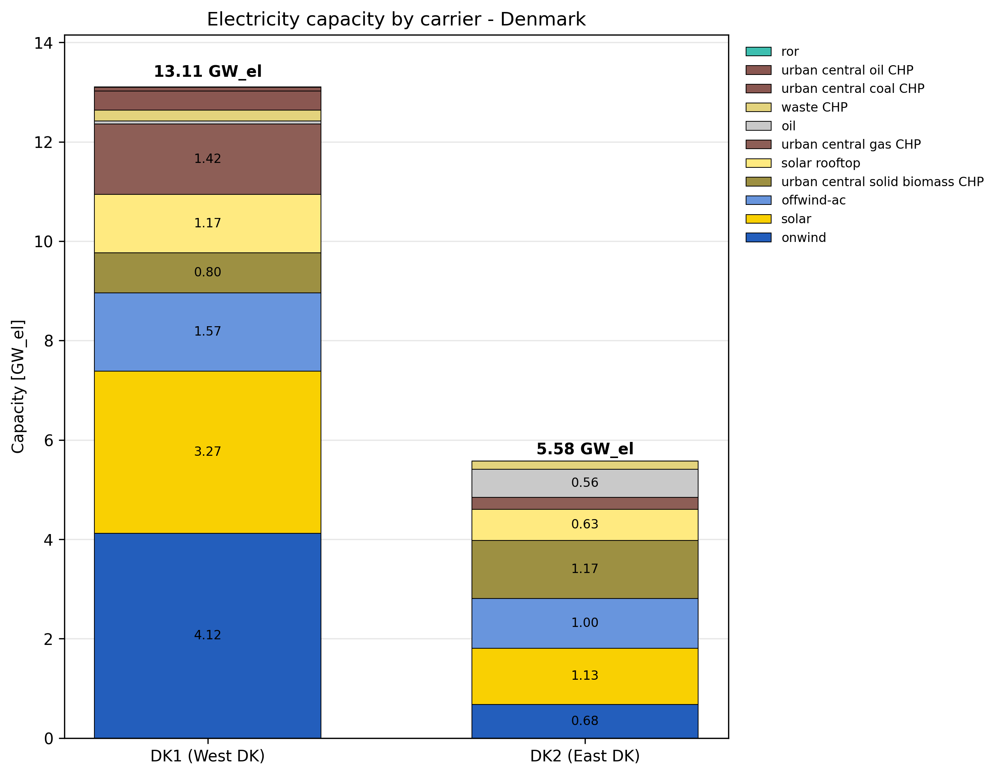

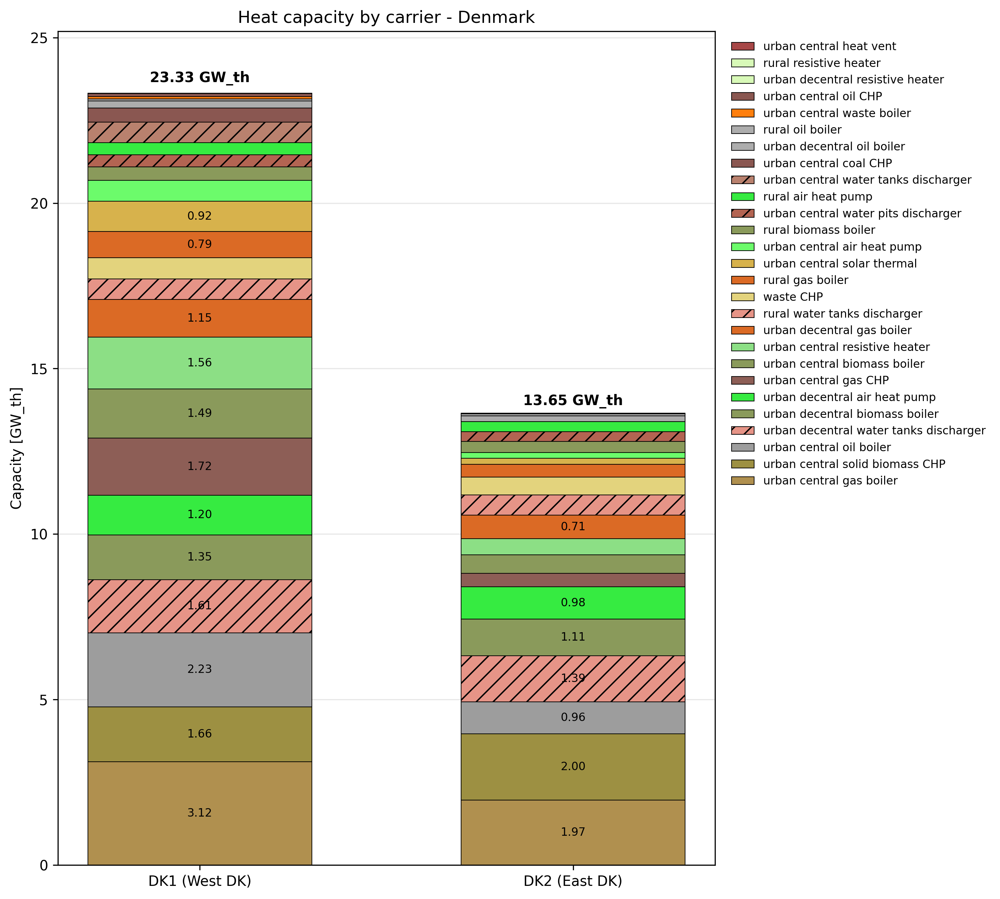

In [7]:
df_el = output_capacities(n, ["AC", "low voltage"])
df_heat = output_capacities(n, ["urban central heat", "urban decentral heat", "rural heat"])
dk_nodes = sorted(x for x in df_el.node.unique() if x.startswith("DK"))
df_heat_tech = df_heat.assign(
    carrier=df_heat.carrier.str.replace(r"^(urban central|urban decentral|rural) ", "", regex=True)
)
plot_stacked_by_node(n, df_heat_tech, "Heat capacity by technology - Denmark", "GW_th", nodes=dk_nodes)
plot_stacked_by_node(n, df_el, "Electricity capacity by carrier - Denmark", "GW_el", nodes=dk_nodes)
plot_stacked_by_node(n, df_heat, "Heat capacity by carrier - Denmark", "GW_th", nodes=dk_nodes,
                     figsize=(10, 9))

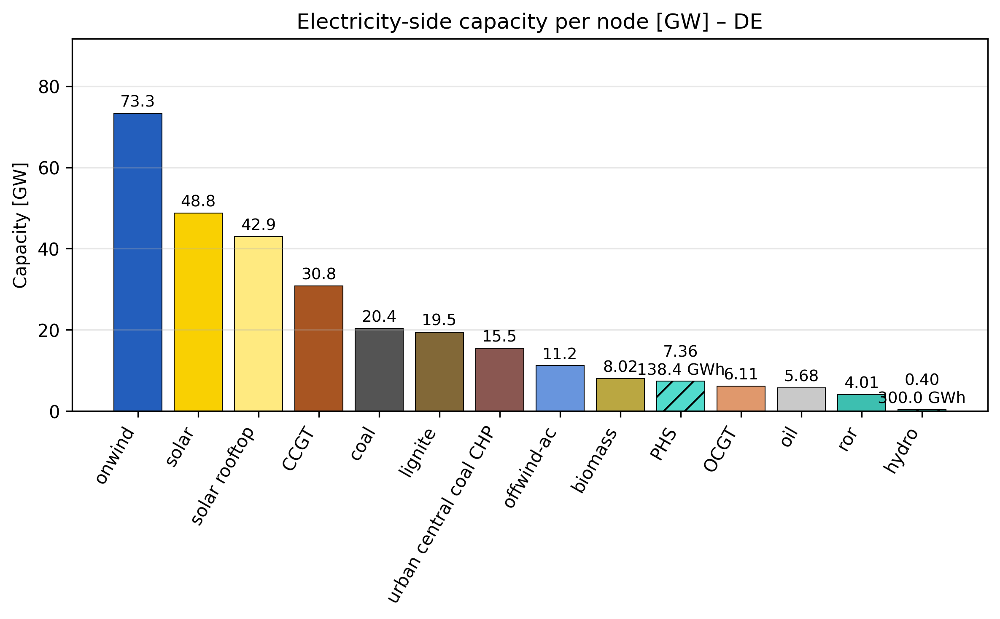

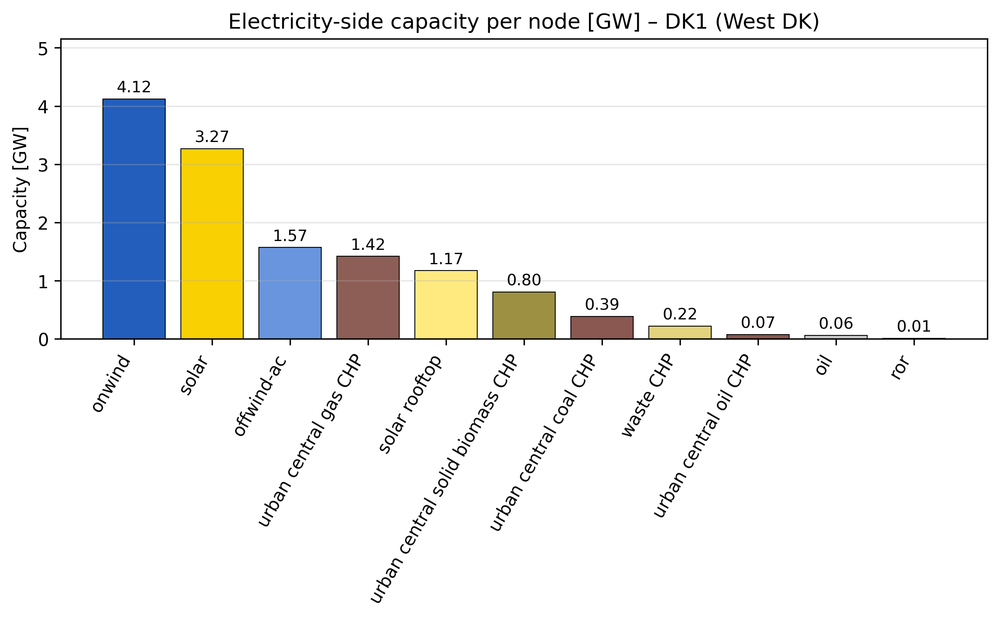

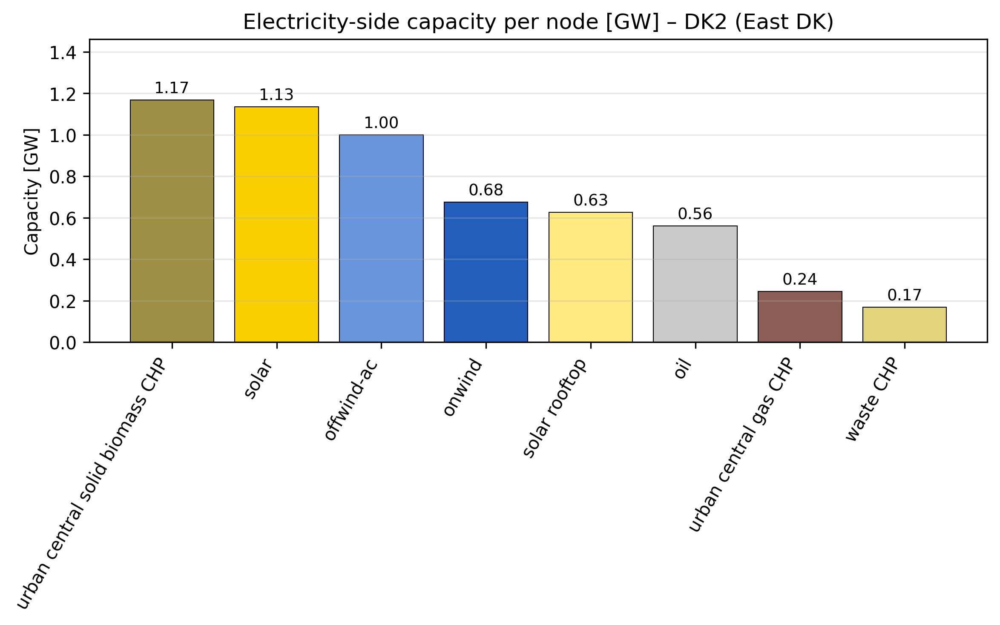

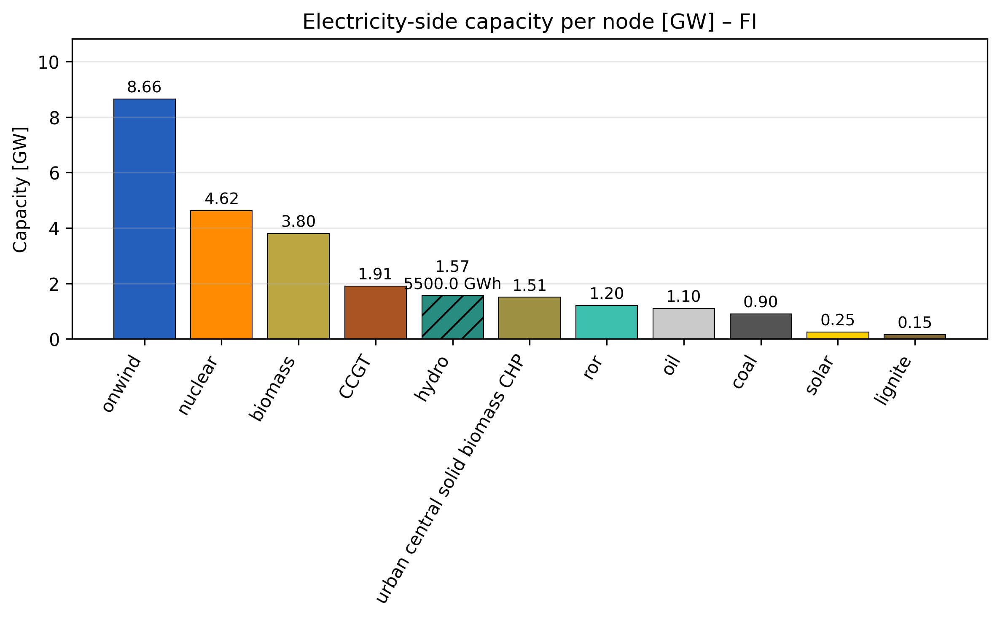

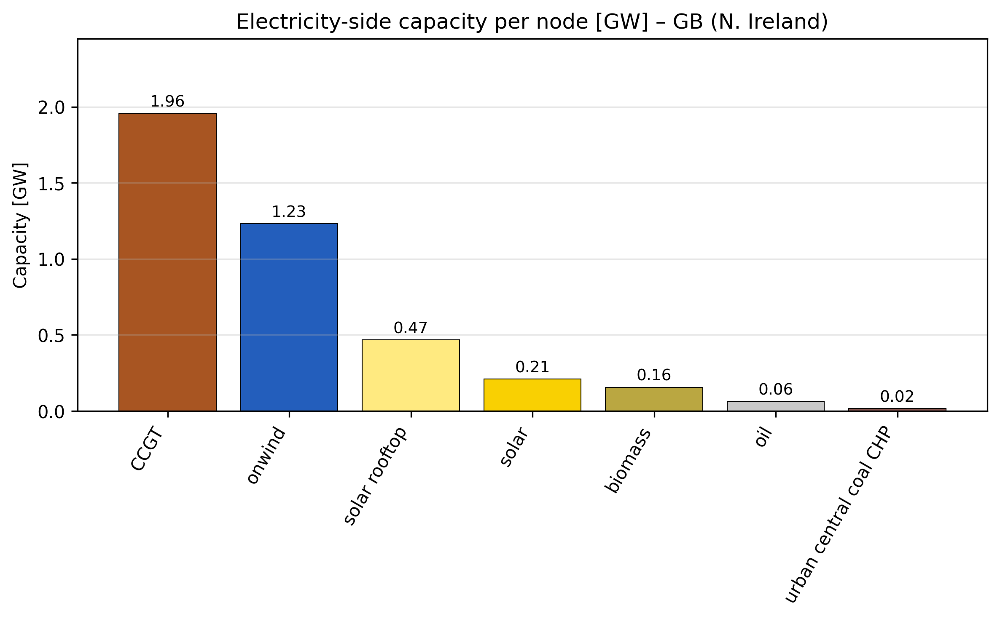

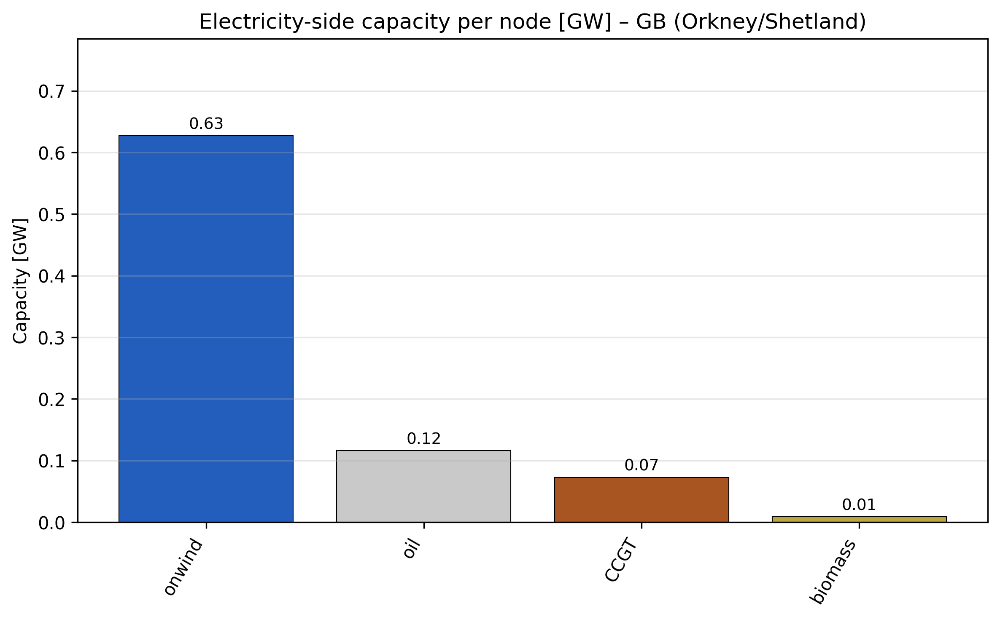

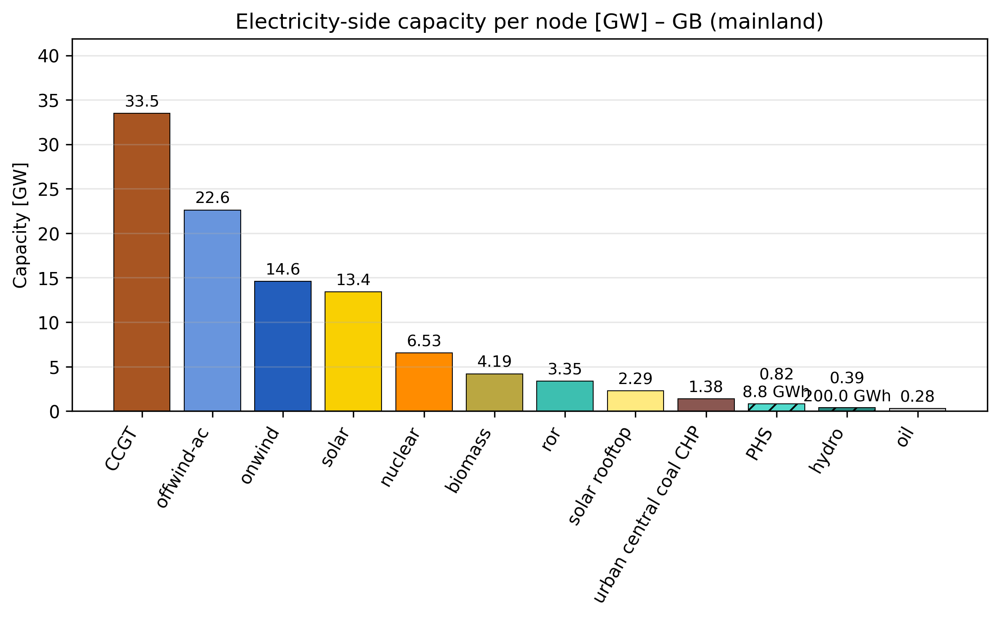

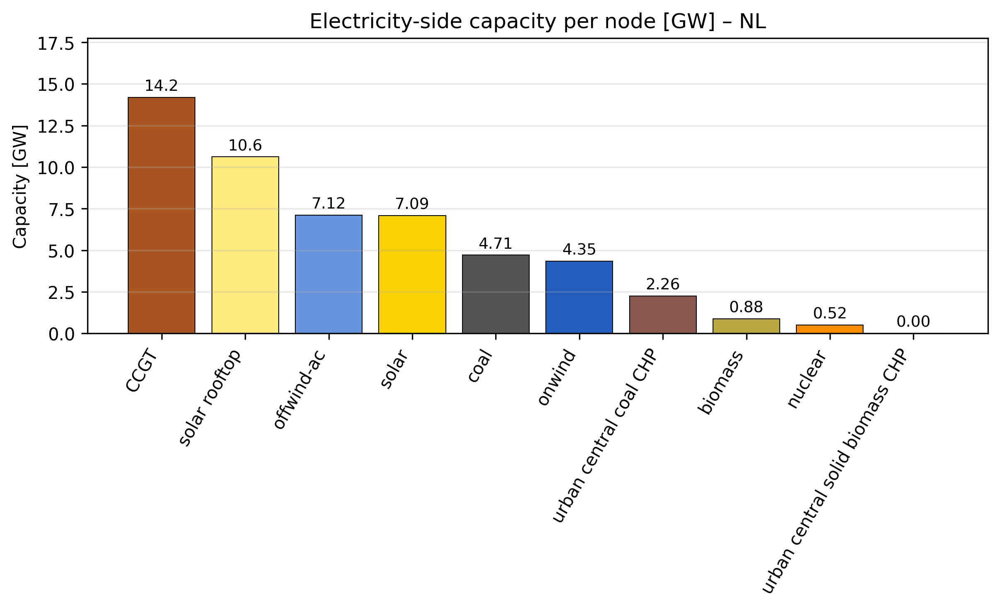

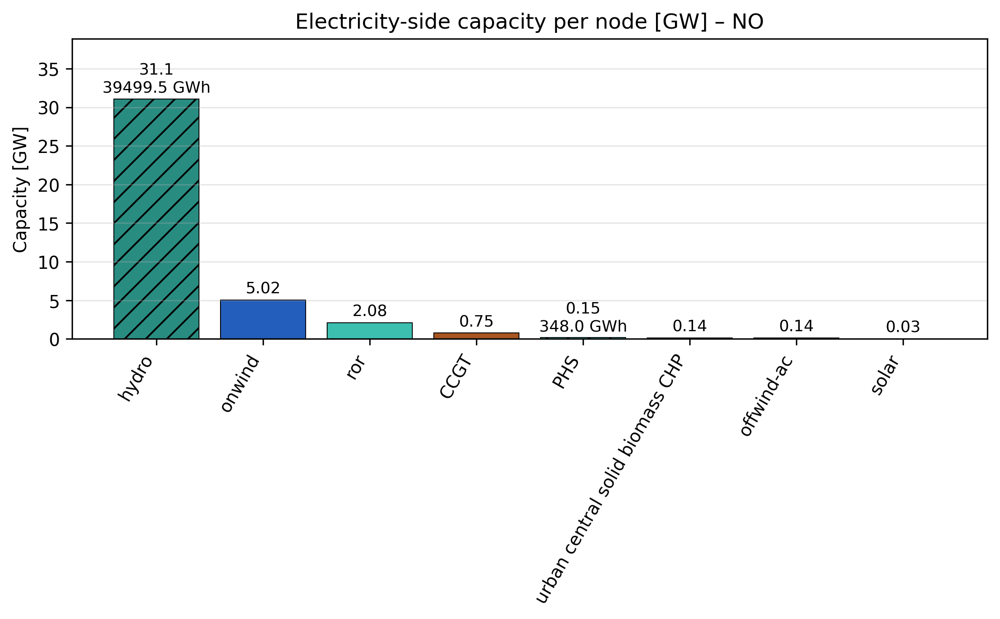

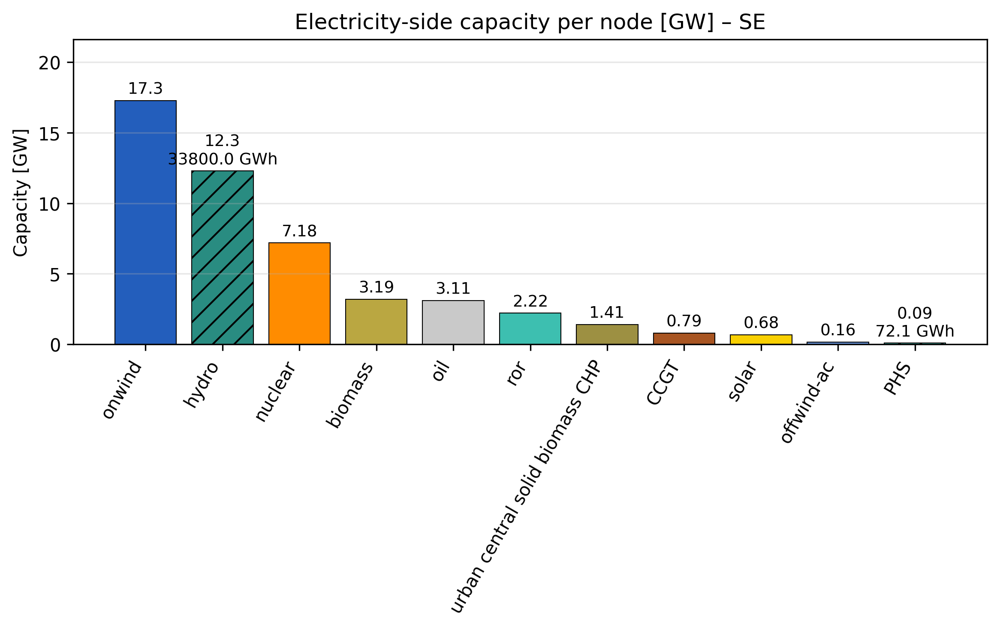

node,DE,DK1 (West DK),DK2 (East DK),FI,GB (N. Ireland),GB (Orkney/Shetland),GB (mainland),NL,NO,SE
carrier,,,,,,,,,,
CCGT,30.783,NaN,NaN,1.907,1.957,0.073,33.491,14.199,0.753,0.790
OCGT,6.113,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PHS,7.362,NaN,NaN,NaN,NaN,NaN,0.824,NaN,0.152,0.091
biomass,8.020,NaN,NaN,3.801,0.156,0.009,4.186,0.877,NaN,3.186
coal,20.352,NaN,NaN,0.903,NaN,NaN,NaN,4.706,NaN,NaN
hydro,0.402,NaN,NaN,1.568,NaN,NaN,0.387,NaN,31.095,12.304
lignite,19.457,NaN,NaN,0.150,NaN,NaN,NaN,NaN,NaN,NaN
nuclear,NaN,NaN,NaN,4.622,NaN,NaN,6.534,0.515,NaN,7.184
offwind-ac,11.164,1.575,1.000,NaN,NaN,NaN,22.621,7.121,0.138,0.158


In [8]:
#Cell 1 – Electricity capacity per node

df_el = output_capacities(n, ["AC", "low voltage"])
plot_capacity_by_node(n, df_el, "Electricity-side capacity per node [GW]")
df_el.pivot(index="carrier", columns="node", values="cap").round(3)

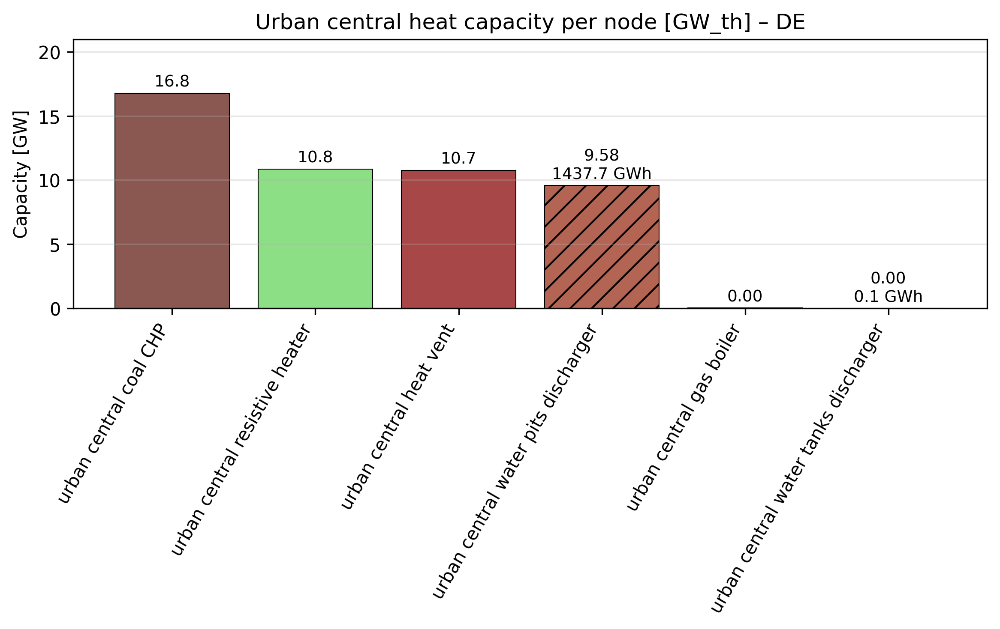

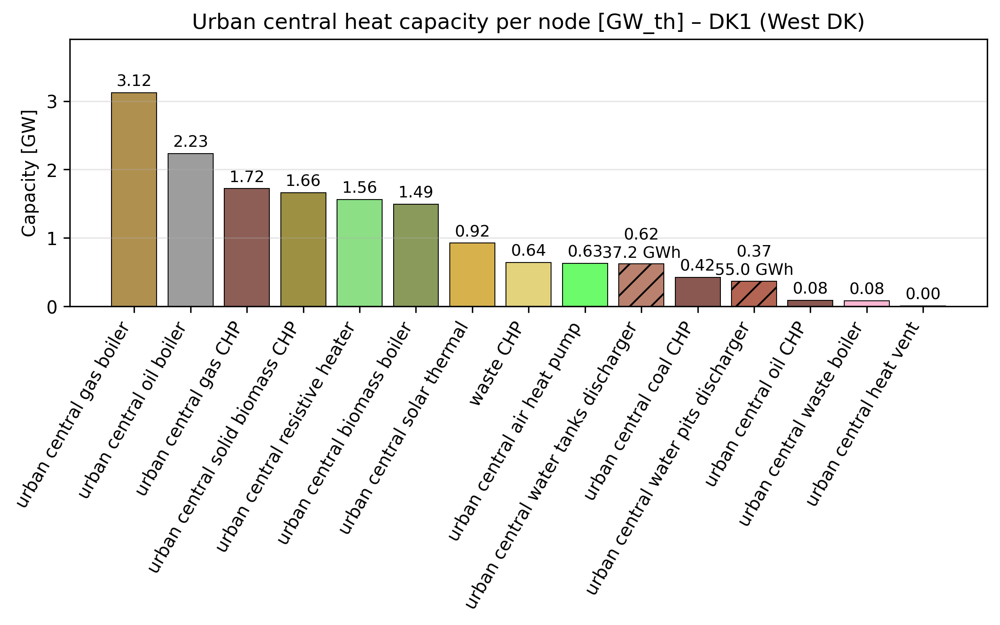

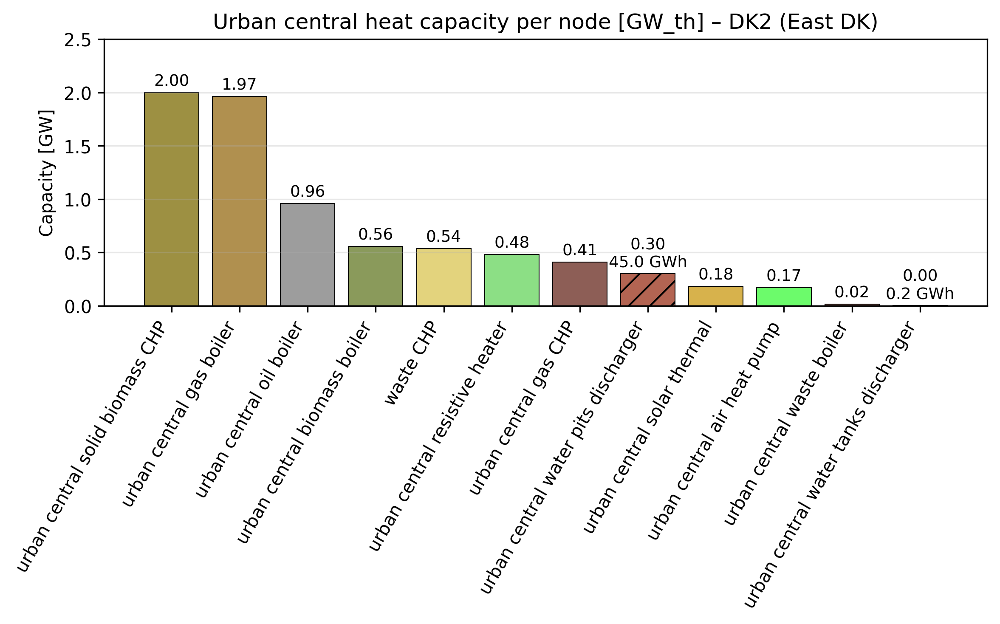

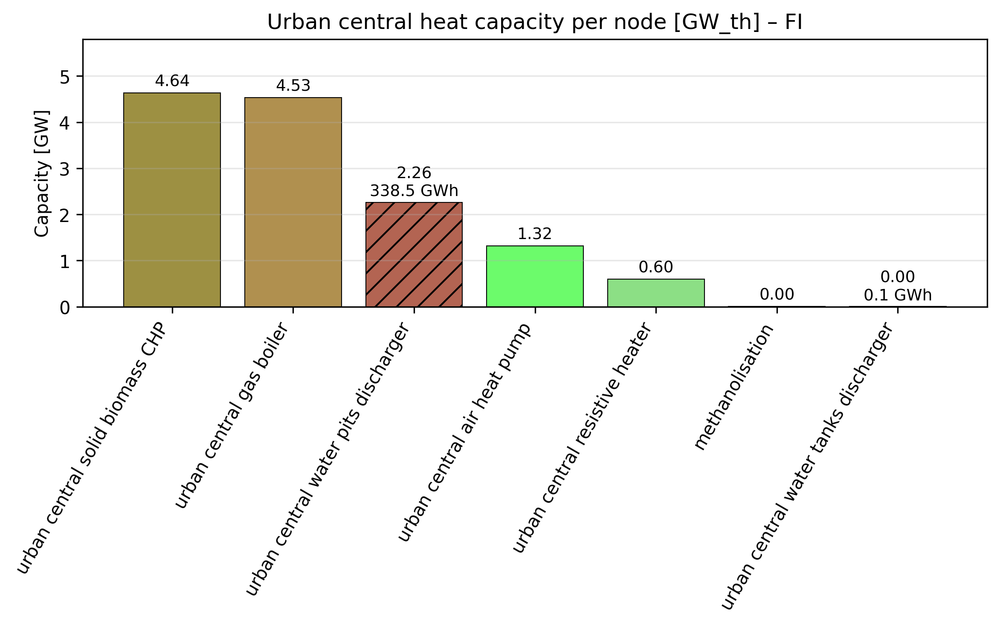

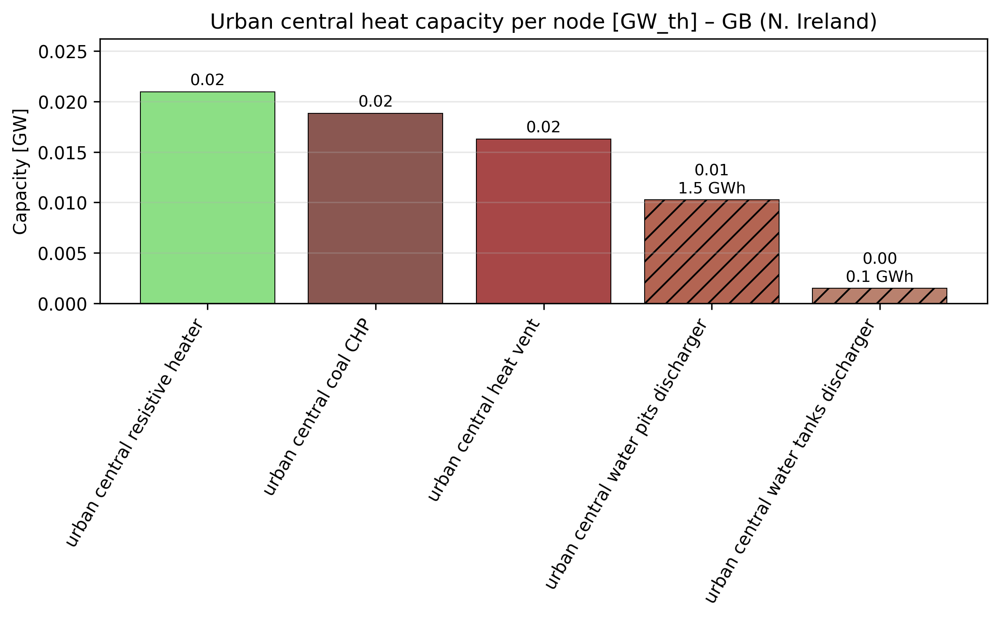

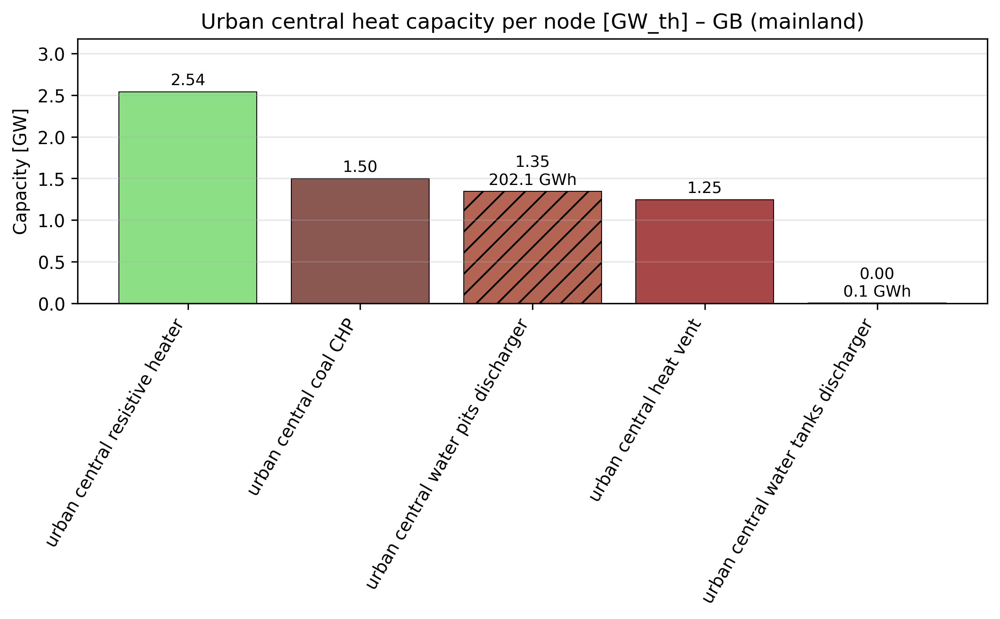

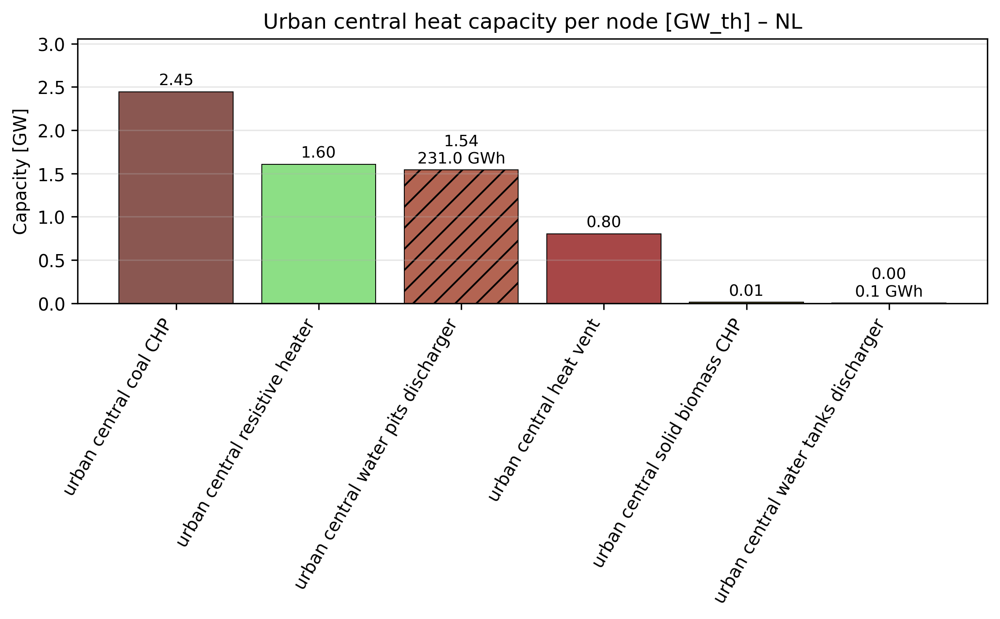

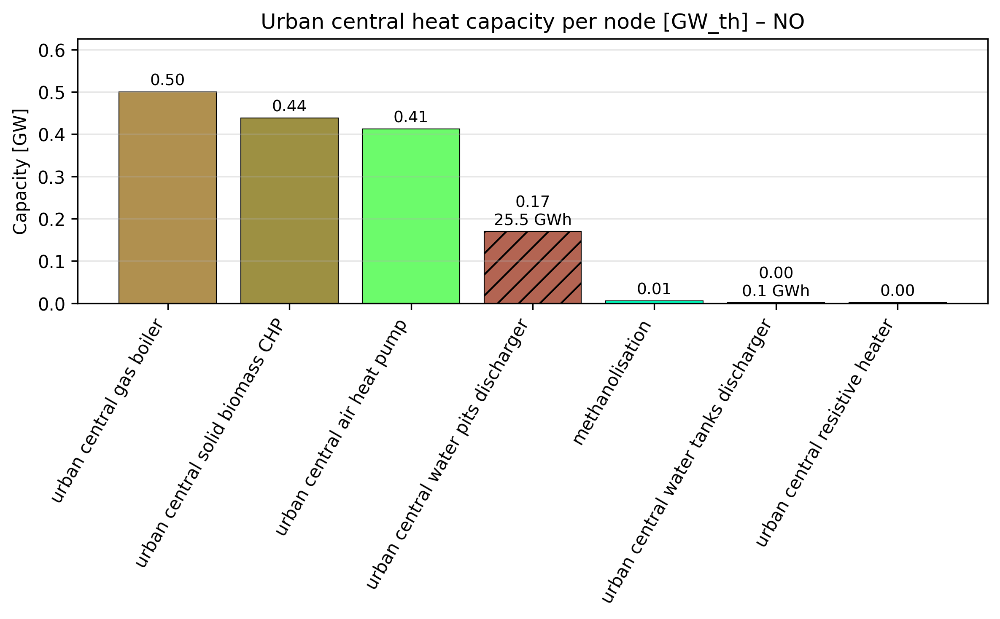

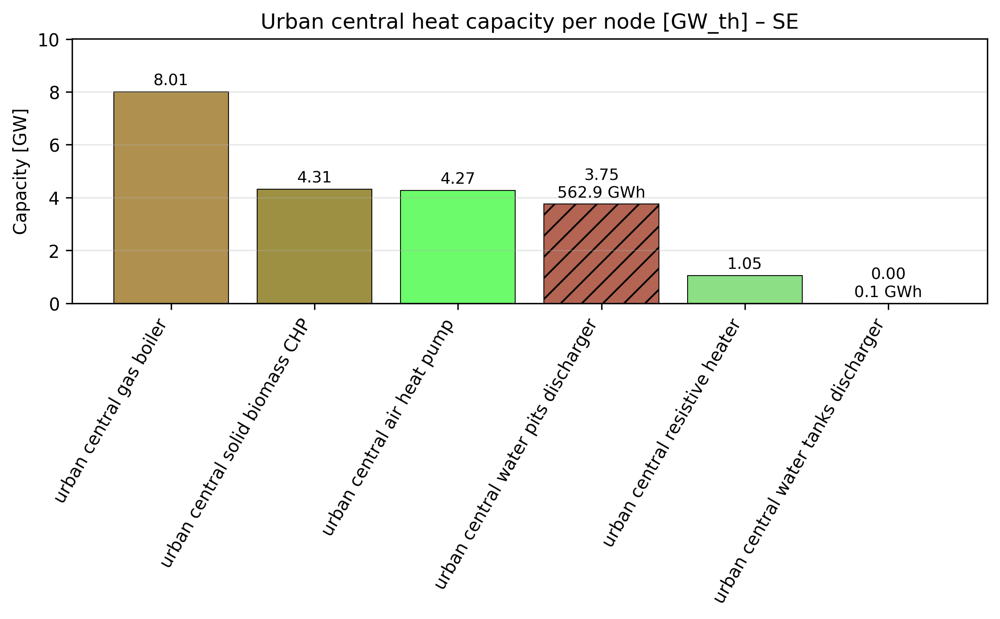

node,DE,DK1 (West DK),DK2 (East DK),FI,GB (N. Ireland),GB (mainland),NL,NO,SE
carrier,,,,,,,,,
methanolisation,NaN,NaN,NaN,0.003,NaN,NaN,NaN,0.005,NaN
urban central air heat pump,NaN,0.626,0.169,1.320,NaN,NaN,NaN,0.412,4.272
urban central biomass boiler,NaN,1.490,0.557,NaN,NaN,NaN,NaN,NaN,NaN
urban central coal CHP,16.771,0.422,NaN,NaN,0.019,1.495,2.445,NaN,NaN
urban central gas CHP,NaN,1.721,0.409,NaN,NaN,NaN,NaN,NaN,NaN
urban central gas boiler,0.004,3.124,1.965,4.532,NaN,NaN,NaN,0.500,8.006
urban central heat vent,10.736,0.004,NaN,NaN,0.016,1.246,0.802,NaN,NaN
urban central oil CHP,NaN,0.083,NaN,NaN,NaN,NaN,NaN,NaN,NaN
urban central oil boiler,NaN,2.231,0.959,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
#Cell 2 – Urban central heat capacity per node
df_uc = output_capacities(n, ["urban central heat"])
plot_capacity_by_node(n, df_uc, "Urban central heat capacity per node [GW_th]")
df_uc.pivot(index="carrier", columns="node", values="cap").round(3)

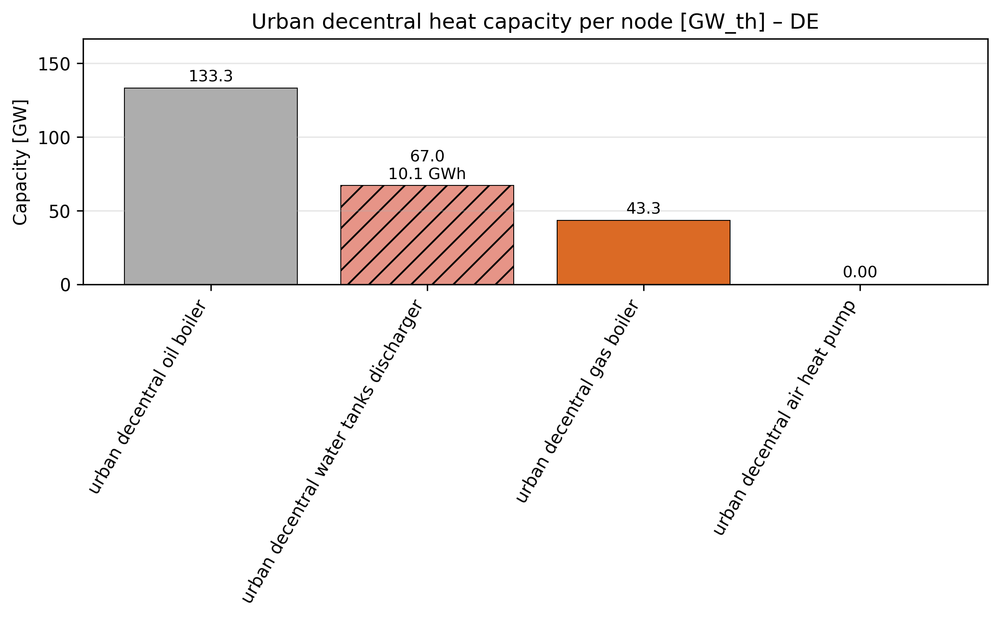

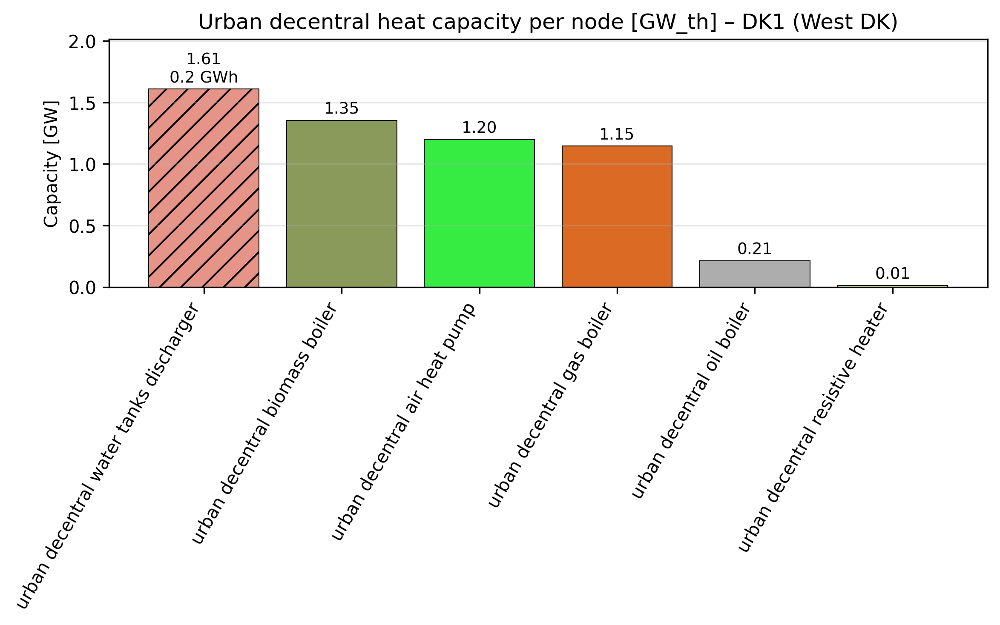

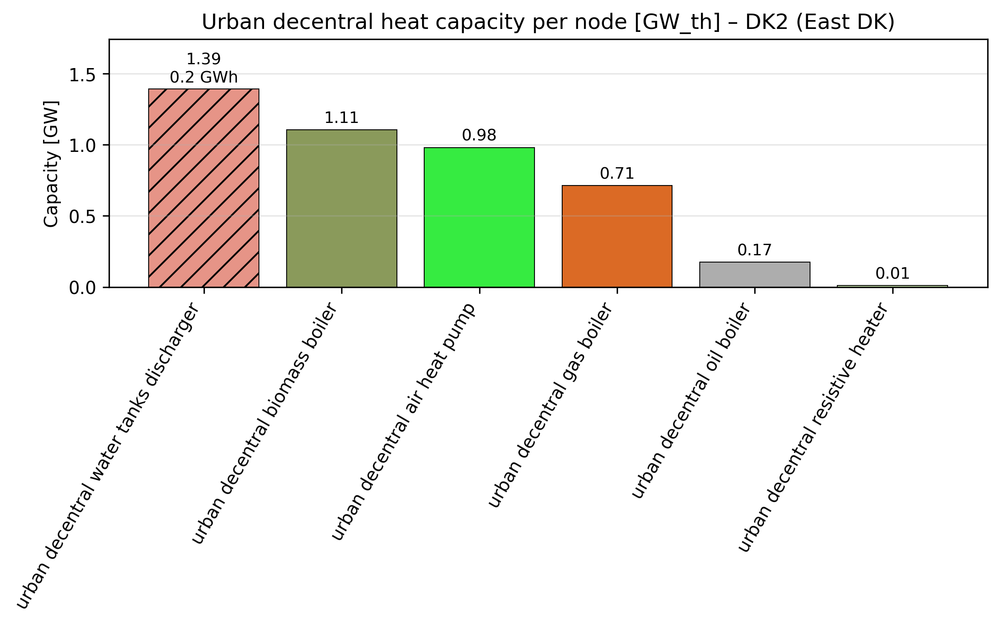

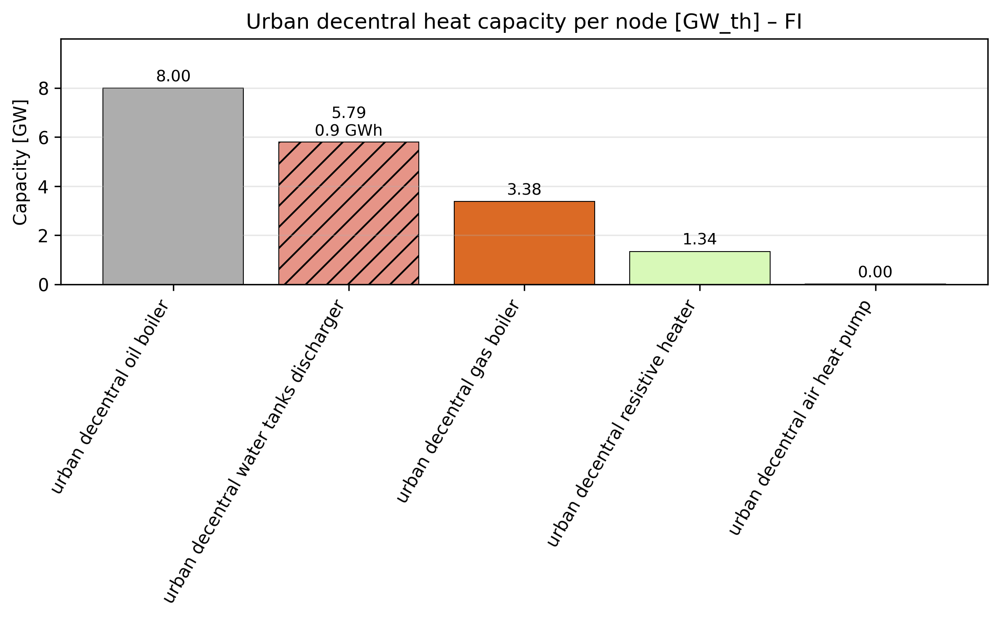

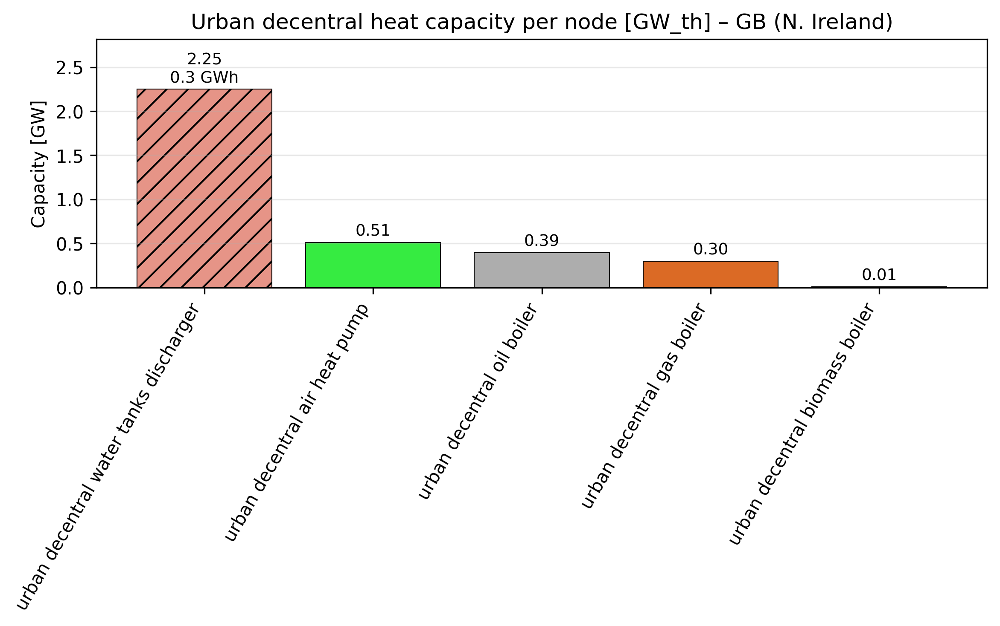

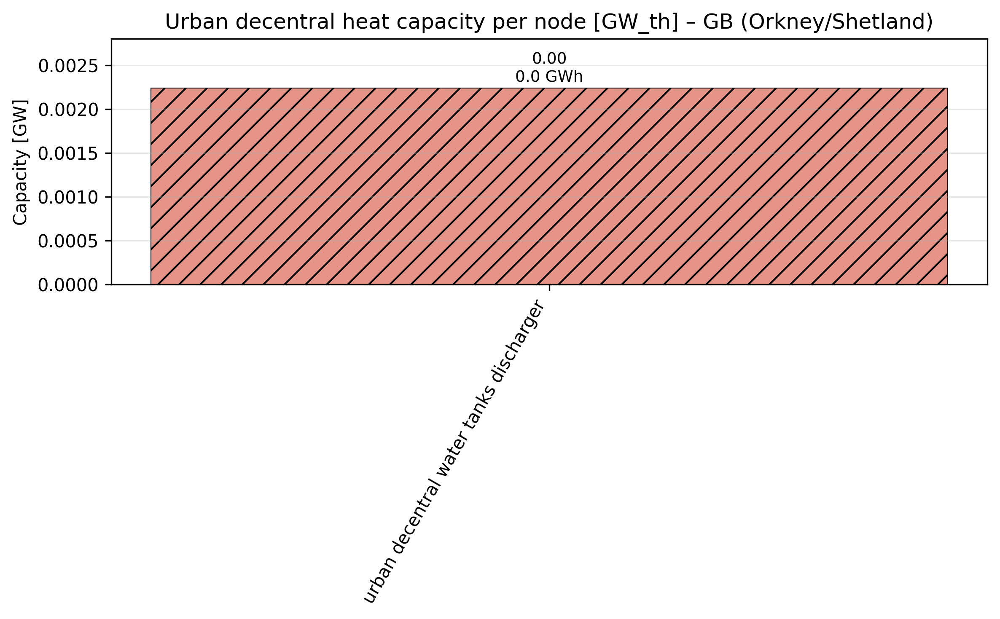

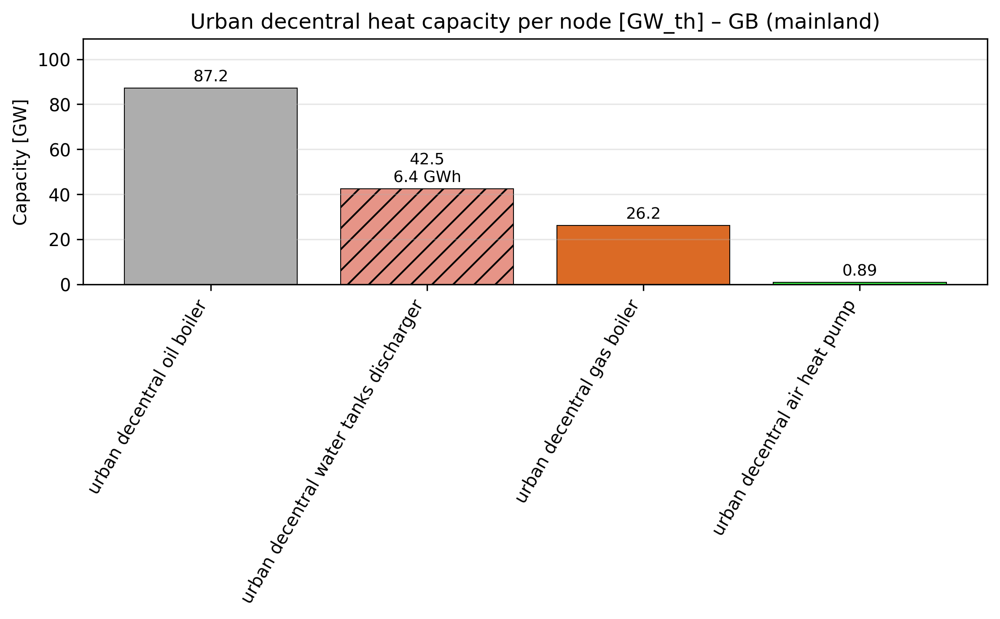

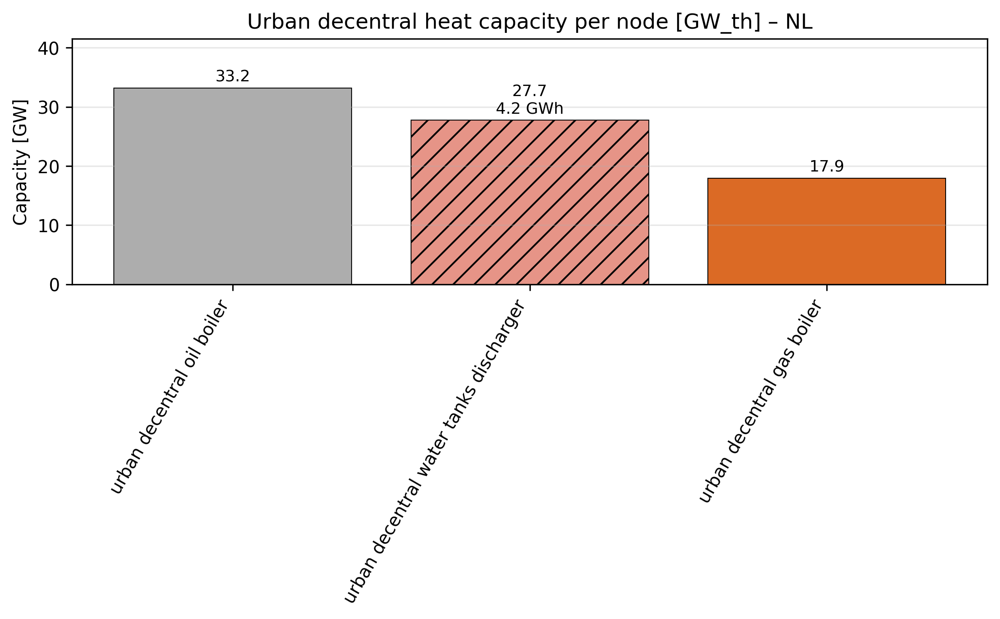

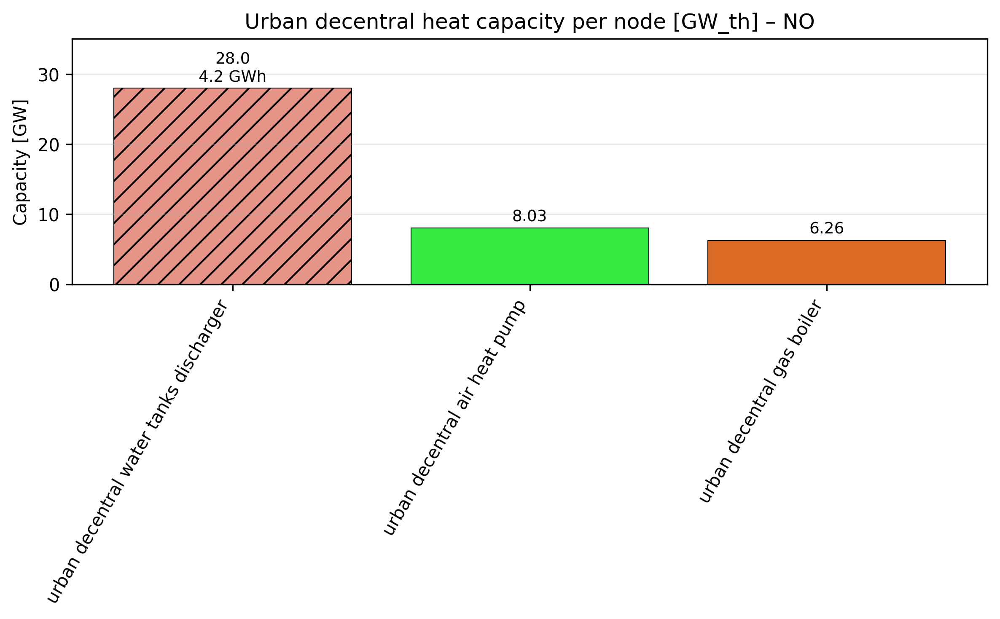

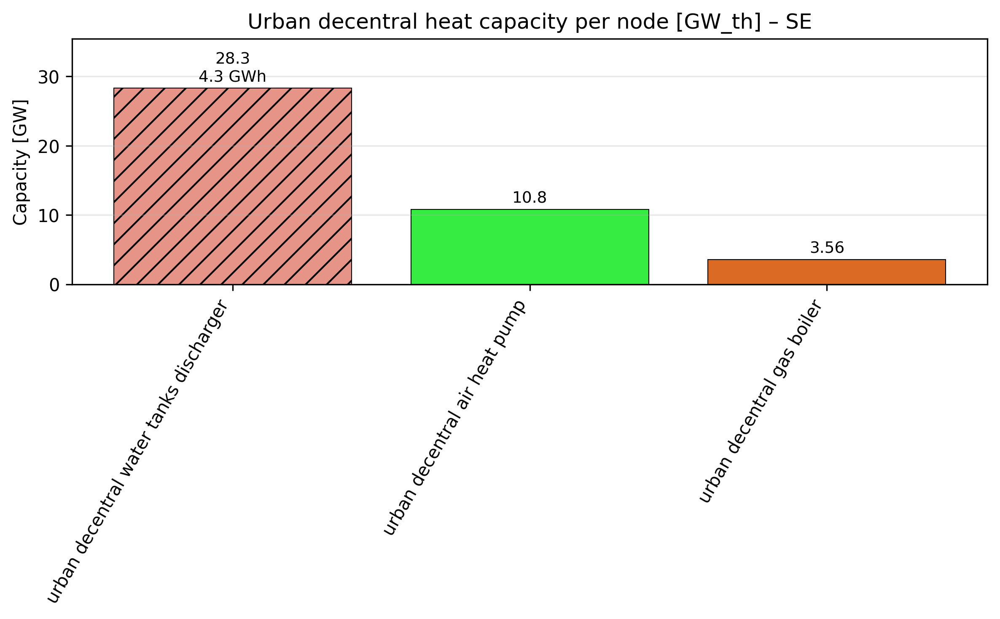

node,DE,DK1 (West DK),DK2 (East DK),FI,GB (N. Ireland),GB (Orkney/Shetland),GB (mainland),NL,NO,SE
carrier,,,,,,,,,,
urban decentral air heat pump,0.004,1.199,0.981,0.003,0.511,NaN,0.893,NaN,8.026,10.809
urban decentral biomass boiler,NaN,1.352,1.106,NaN,0.007,NaN,NaN,NaN,NaN,NaN
urban decentral gas boiler,43.332,1.147,0.714,3.379,0.298,NaN,26.194,17.893,6.259,3.562
urban decentral oil boiler,133.310,0.213,0.174,7.998,0.393,NaN,87.229,33.196,NaN,NaN
urban decentral resistive heater,NaN,0.011,0.009,1.339,NaN,NaN,NaN,NaN,NaN,NaN
urban decentral water tanks discharger,67.012,1.611,1.394,5.789,2.252,0.002,42.502,27.743,28.032,28.342


In [10]:
#Cell 3 – Urban decentral heat capacity per node
df_ud = output_capacities(n, ["urban decentral heat"])
plot_capacity_by_node(n, df_ud, "Urban decentral heat capacity per node [GW_th]")
df_ud.pivot(index="carrier", columns="node", values="cap").round(3)

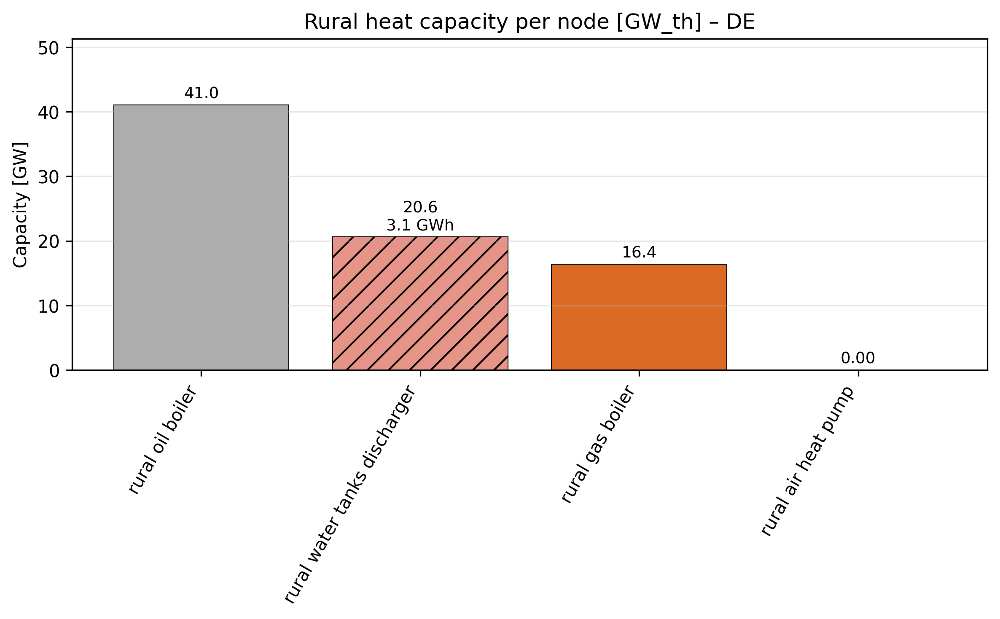

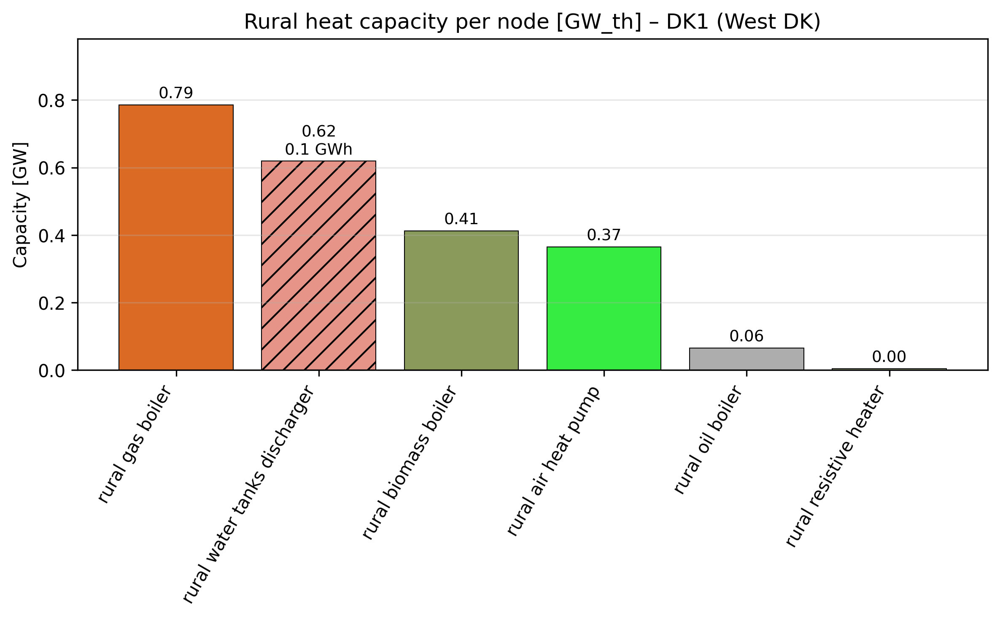

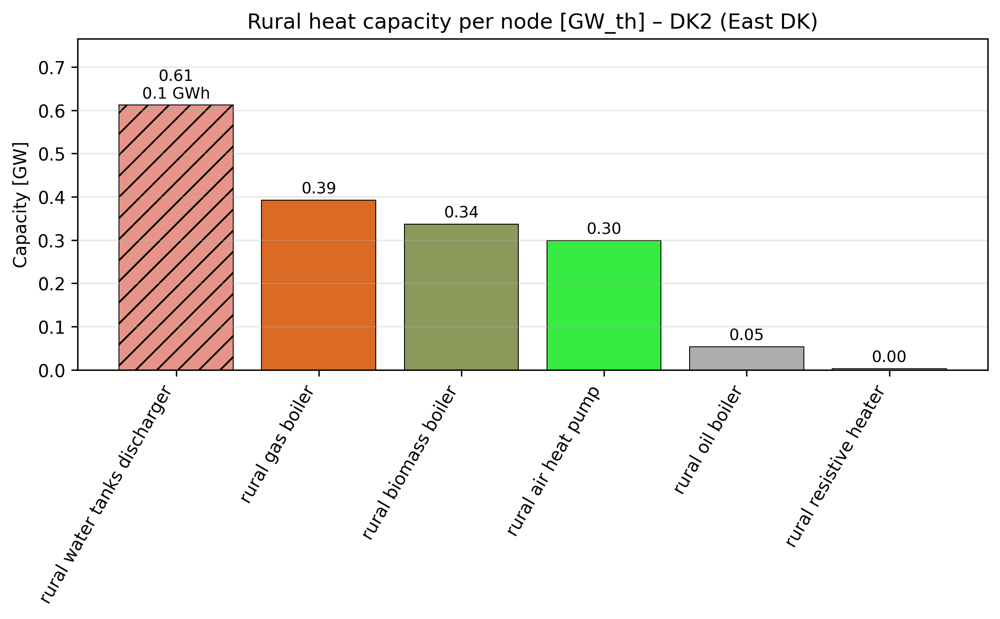

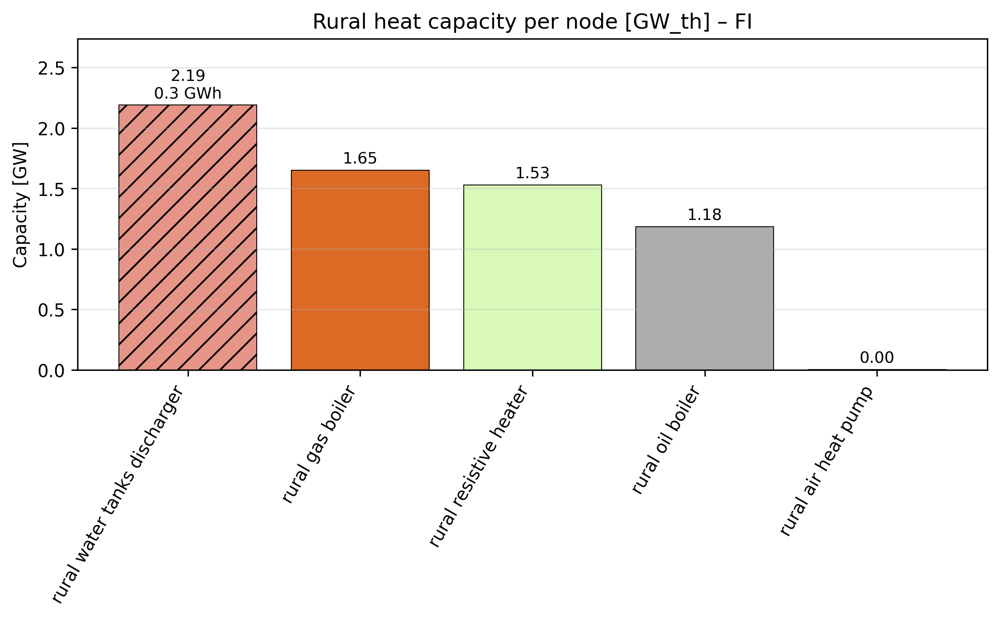

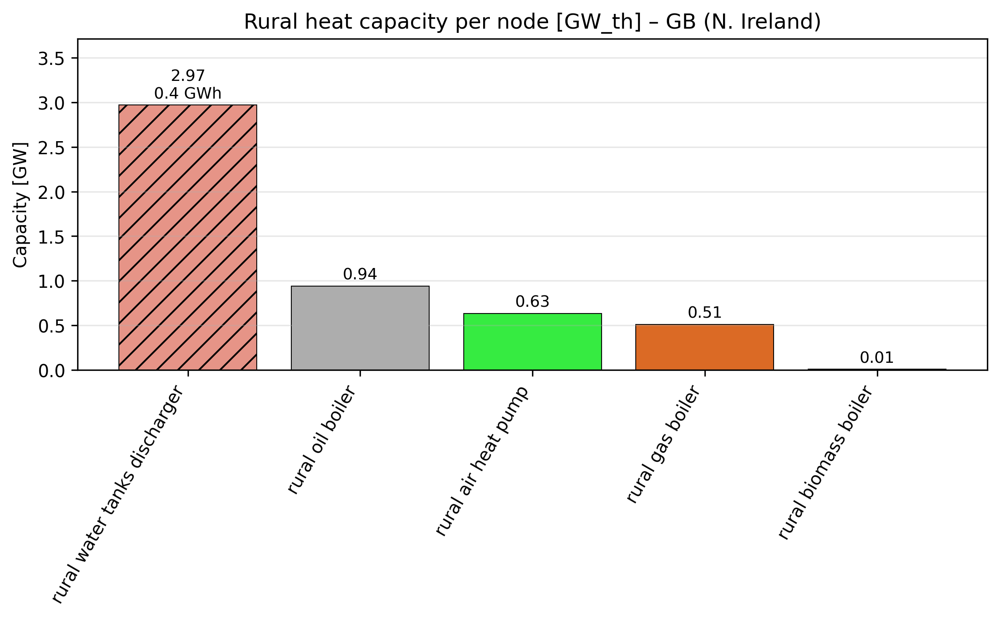

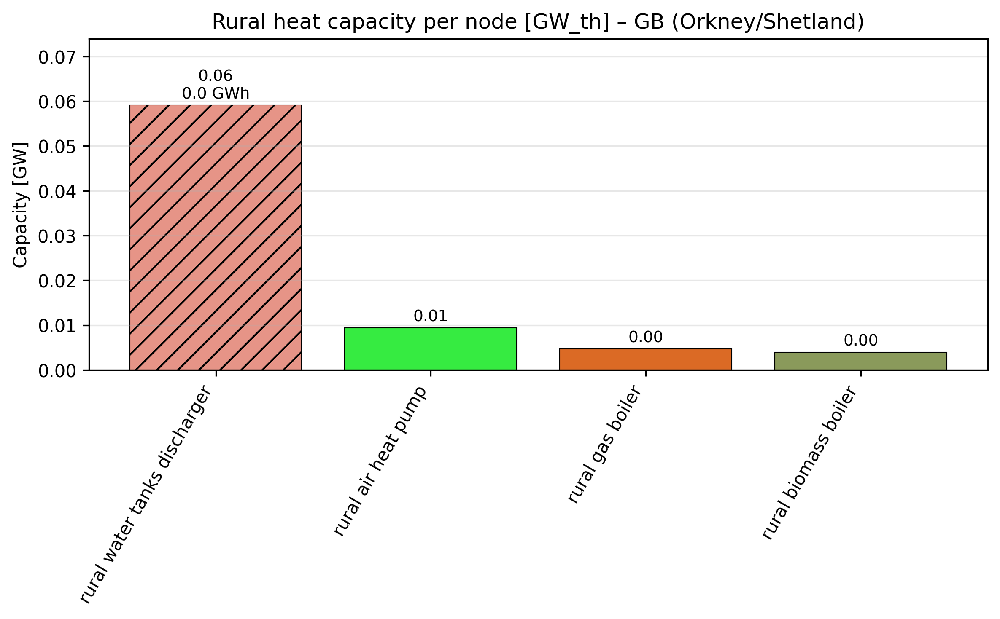

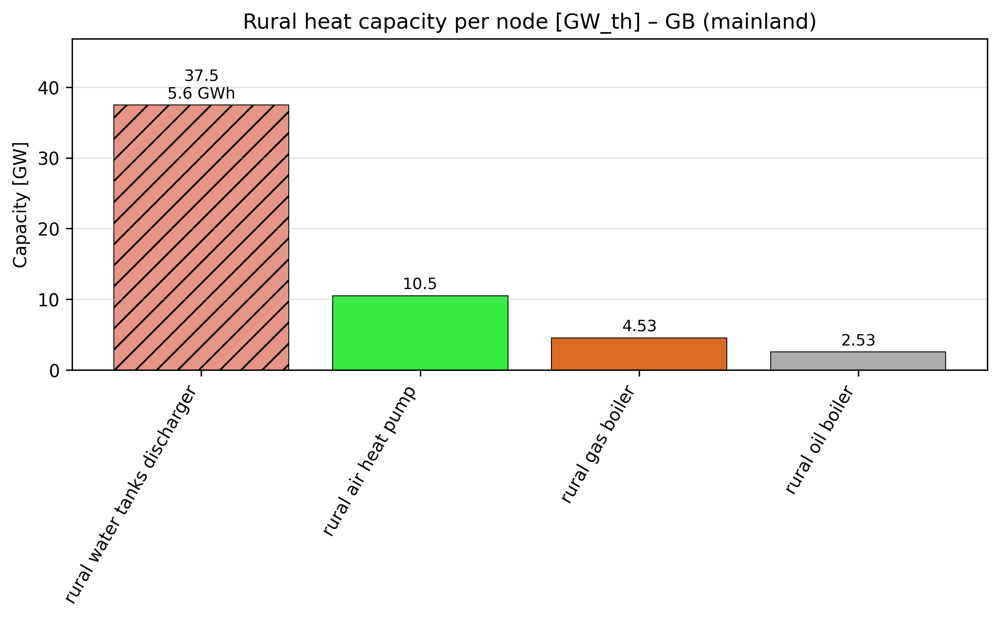

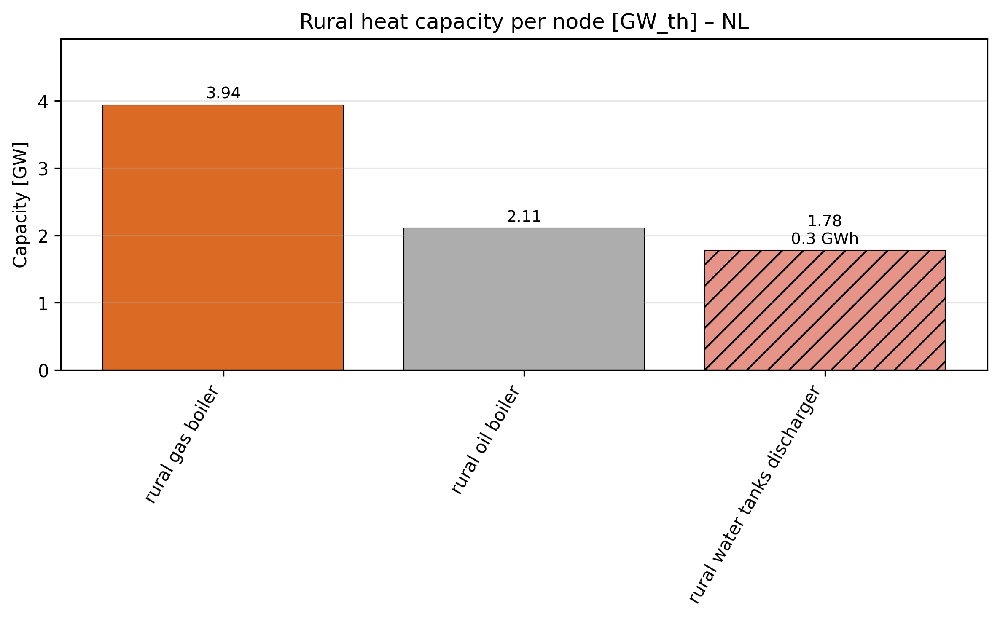

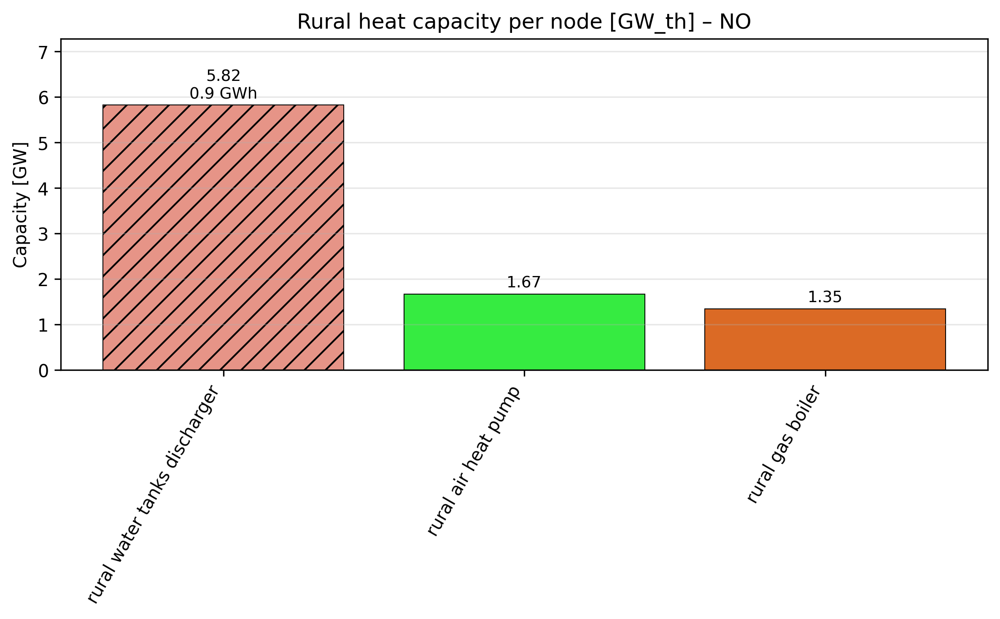

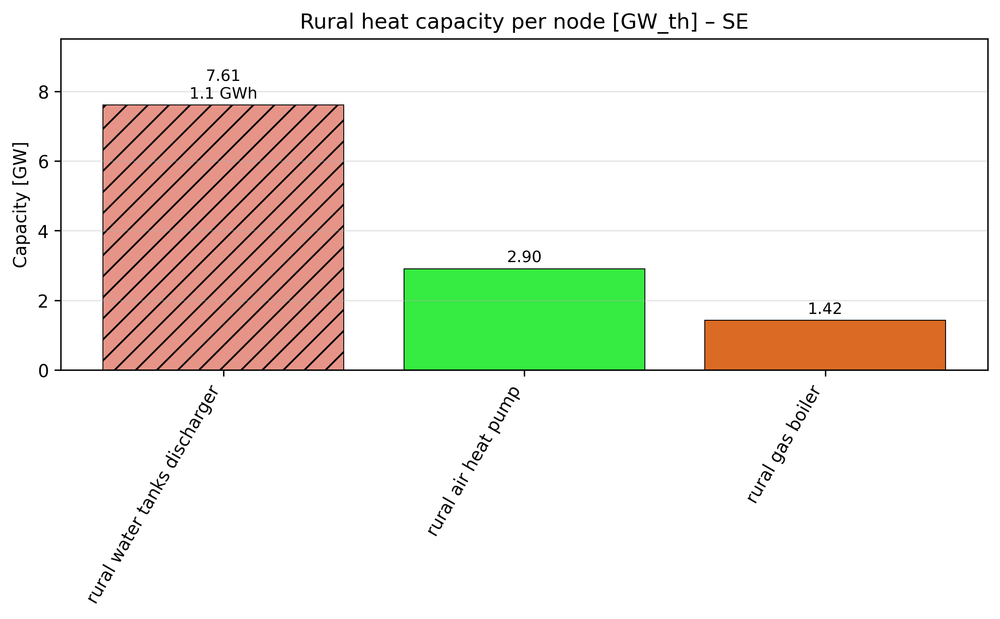

node,DE,DK1 (West DK),DK2 (East DK),FI,GB (N. Ireland),GB (Orkney/Shetland),GB (mainland),NL,NO,SE
carrier,,,,,,,,,,
rural air heat pump,0.004,0.365,0.299,0.003,0.634,0.009,10.460,NaN,1.666,2.899
rural biomass boiler,NaN,0.412,0.337,NaN,0.007,0.004,NaN,NaN,NaN,NaN
rural gas boiler,16.404,0.785,0.392,1.651,0.508,0.005,4.528,3.938,1.347,1.424
rural oil boiler,41.039,0.065,0.053,1.184,0.940,NaN,2.527,2.110,NaN,NaN
rural resistive heater,NaN,0.003,0.003,1.529,NaN,NaN,NaN,NaN,NaN,NaN
rural water tanks discharger,20.649,0.619,0.612,2.189,2.970,0.059,37.469,1.777,5.824,7.609


In [11]:
#Cell 4 – Rural heat capacity per node
df_rh = output_capacities(n, ["rural heat"])
plot_capacity_by_node(n, df_rh, "Rural heat capacity per node [GW_th]")
df_rh.pivot(index="carrier", columns="node", values="cap").round(3)